# Visual Evidence Candidate-Survival Kit (Colab T4)

**What this measures.** When a fast dense retriever keeps only **B = 10 / 25 / 50 / 100** candidates for a stronger late-interaction reranker, how many *human-annotated relevant pages* survive, and where are they lost: at the candidate stage or inside the reranker? Data: ViDoRe v3 *computer_science* (pinned revision), **110 human-origin English queries**. Model: `Hcompany/NeoMME-260M-Retriever` (pinned), **one forward pass** gives dense and multivector embeddings. Store/retrieve: a pinned local **Qdrant v1.19.2** server.

**What it is not.** A diagnostic, not a leaderboard reproduction (pages are resized to a **1024 px** longest side, the model default is 2048) and not a claim that reranking helps. It measures *label survival and ranking*, not answer correctness. Score 1 = critically relevant (needs additional info), score 2 = page can contain the complete answer; "all annotated pages covered" is **not** answer completeness. Unjudged pages are not established negatives.

**How to run.** Runtime → *Change runtime type* → **T4 GPU**, then *Run all*. The defaults run `MODE="full"` (after a quick isolated smoke check, `RUN_SMOKE_FIRST`). Smoke = 8 queries / 256 real pages, a qrel-aware *engineering* fixture, never comparable to full results; set `MODE="smoke"` to run only that. Set `FULL_LATE_REFERENCE=False` to skip the optional unrestricted late-interaction reference.

**If a stage fails.** Fix the cause and re-run the same cell; completed pages/queries are skipped. Out of VRAM: lower `DOC_BATCH`/`QUERY_BATCH` (do not change dtype or resolution mid-run; a different `PRESET` is a new run). Pins/torch problem: restart the session and run from the top. "Refusing stale cache": you changed the preset/config; set a new `RUN_TAG`.

**Restart / resume.** The install cell may require **Runtime → Restart session** (it says so explicitly); after a restart run again from the top, the install cell becomes a no-op. Embeddings, Qdrant upserts and per-query results are checkpointed per item with checksums; after a disconnect just re-run the cells (set `USE_DRIVE=True` to keep checkpoints across sessions). Nothing is published; no paid service or secret is needed.

In [1]:
# ---- 0. Configuration (edit here) -------------------------------------------------------------
MODE = "full"               # "full" = scientific target (1,360 pages, 110 queries);  "smoke" = engineering fixture (8 queries / 256 pages)
PRESET = "primary_1024"     # "primary_1024" (longest side 1024 px, T4-friendly) | "optional_2048" (model default cap; separate cache)
USE_DRIVE = False           # True: mount Drive for DURABLE cache/results only (the live Qdrant DB stays on /content)
FULL_LATE_REFERENCE = True  # optional (set False to skip) unrestricted full-corpus late-interaction reference (time reported separately)
RUN_SMOKE_FIRST = True      # when MODE=="full": first run the smoke fixture end-to-end (cheap, isolated directory)
RUN_TAG = ""                # change to start a NEW run instead of reusing/refusing an existing cache
DOC_BATCH, QUERY_BATCH = 1, 4   # start at 1 / 4; if VRAM is short lower these (never switch dtype/resolution silently)
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"   # quieter logs; our own tqdm bars stay

## 1. Install (inspects the existing GPU torch first; never replaces it)

In [2]:
import importlib.metadata as md, subprocess, sys, os

PINS = {"transformers": "5.19.0", "sentence-transformers": "6.1.0", "qdrant-client": "1.19.1", "datasets": "5.1.0"}
ver = lambda n: (md.version(n) if n in {d.metadata["Name"] for d in md.distributions()} else None)

torch_v, tv_v = ver("torch"), ver("torchvision")
print("existing torch:", torch_v, "| torchvision:", tv_v)
assert torch_v and tv_v, "A GPU-enabled torch + torchvision must already be installed (Colab ships them). NeoMME's image processor needs torchvision."
assert "+cpu" not in torch_v, "CPU-only torch detected; use a GPU runtime (Runtime > Change runtime type > T4 GPU)."
import torch
print("CUDA runtime:", torch.version.cuda, "| cuda available:", torch.cuda.is_available())
if torch.cuda.is_available():
    cc = torch.cuda.get_device_capability(0)
    print("GPU:", torch.cuda.get_device_name(0), "| compute capability", cc, "| bf16 supported:", torch.cuda.is_bf16_supported())
    # T4 = sm_75: the Colab torch wheel supports it; no wheel change is made or needed.
    assert f"sm_{cc[0]}{cc[1]}" in torch.cuda.get_arch_list() or any(a.startswith("compute_") for a in torch.cuda.get_arch_list()), "torch wheel lacks this GPU architecture"

need = [f"{k}=={v}" for k, v in PINS.items() if ver(k) != v]
already_imported = [m for m in ("transformers", "sentence_transformers", "qdrant_client", "datasets") if m in sys.modules]
if need:
    # Constraints freeze the existing torch/torchvision so resolving the pins cannot swap the CUDA wheel.
    open("/content/constraints_gpu_torch.txt", "w").write(f"torch=={torch_v}\ntorchvision=={tv_v}\n")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *need, "psutil", "matplotlib", "tqdm",
                           "-c", "/content/constraints_gpu_torch.txt"])
    print("installed:", need)
else:
    print("pins already satisfied")
assert ver("torch") == torch_v and ver("torchvision") == tv_v, "torch/torchvision changed during install: restart the runtime and inspect"
bad = {k: ver(k) for k, v in PINS.items() if ver(k) != v}
assert not bad, f"pins not satisfied: {bad}"
if need and already_imported:
    print("\n>>> RESTART REQUIRED: packages were imported before being re-pinned. Runtime > Restart session, then run from the top. <<<")
else:
    print("environment OK (no restart needed)")

existing torch: 2.11.0+cu130 | torchvision: 0.26.0+cu130
CUDA runtime: 13.0 | cuda available: True
GPU: Tesla T4 | compute capability (7, 5) | bf16 supported: True
installed: ['transformers==5.19.0', 'sentence-transformers==6.1.0', 'qdrant-client==1.19.1', 'datasets==5.1.0']
environment OK (no restart needed)


## 2. Write the `vesk` package (shared code, embedded in this notebook)

In [3]:
EMBEDDED = {"src/vesk/__init__.py": "\"\"\"Visual Evidence Candidate-Survival Kit (vesk).\"\"\"\n__version__ = \"0.1.0\"\n", "src/vesk/cache.py": "\"\"\"Individually addressable, checksummed embedding shards (one page / one query per file).\"\"\"\nfrom __future__ import annotations\n\nimport io\nimport json\nfrom pathlib import Path\n\nimport numpy as np\n\nfrom .util import atomic_write_bytes, atomic_write_json, sha256_file\n\n\nclass ShardCache:\n    \"\"\"<root>/<kind>/<id>.npz  + <id>.done.json (written last = completion marker).\"\"\"\n\n    def __init__(self, root, kind: str, identity: dict):\n        self.dir = Path(root) / kind\n        self.dir.mkdir(parents=True, exist_ok=True)\n        self.kind = kind\n        idf = self.dir / \"CACHE_IDENTITY.json\"\n        if idf.exists():\n            old = json.loads(idf.read_text())\n            if old != json.loads(json.dumps(identity, sort_keys=True)):\n                diff = sorted(k for k in set(old) | set(identity) if old.get(k) != identity.get(k))\n                raise RuntimeError(\n                    f\"Refusing stale/incompatible cache at {self.dir}: identity differs in {diff}. \"\n                    \"Use a new run (change run_tag / preset) instead of reusing it.\")\n        else:\n            atomic_write_json(idf, identity)\n\n    def _p(self, key, ext):\n        return self.dir / f\"{int(key):08d}.{ext}\"\n\n    def is_done(self, key) -> bool:\n        return self._p(key, \"done.json\").exists() and self._p(key, \"npz\").exists()\n\n    def done_keys(self):\n        return sorted(int(p.name.split(\".\")[0]) for p in self.dir.glob(\"*.done.json\")\n                      if (self.dir / (p.name.split(\".\")[0] + \".npz\")).exists())\n\n    def write(self, key, arrays: dict, meta: dict):\n        buf = io.BytesIO()\n        np.savez(buf, **arrays)\n        atomic_write_bytes(self._p(key, \"npz\"), buf.getvalue())\n        marker = dict(meta, key=int(key), sha256=sha256_file(self._p(key, \"npz\")),\n                      bytes=self._p(key, \"npz\").stat().st_size)\n        atomic_write_json(self._p(key, \"done.json\"), marker)  # marker last\n\n    def meta(self, key) -> dict:\n        return json.loads(self._p(key, \"done.json\").read_text())\n\n    def read(self, key, verify=True) -> dict:\n        if verify:\n            self.verify(key)\n        with np.load(self._p(key, \"npz\")) as z:\n            return {k: z[k] for k in z.files}\n\n    def verify(self, key):\n        m = self.meta(key)\n        got = sha256_file(self._p(key, \"npz\"))\n        if got != m[\"sha256\"]:\n            raise RuntimeError(f\"checksum mismatch for {self.kind}/{key}: cache corrupt; delete shard to recompute\")\n\n    def verify_all(self):\n        for k in self.done_keys():\n            self.verify(k)\n        return len(self.done_keys())\n", "src/vesk/cli.py": "\"\"\"python -m vesk.cli {smoke|full} --root DIR [--full-late] [--preset ...] [--stage ...]\"\"\"\nfrom __future__ import annotations\n\nimport argparse\nimport sys\n\nfrom .config import PRESETS, RunConfig\nfrom .pipeline import Run\n\nSTAGES = [\"preflight\", \"data\", \"calibrate\", \"embed\", \"reverify\", \"qdrant\", \"index\", \"parity\", \"evaluate\", \"analyze\", \"export\"]\n\n\ndef main(argv=None):\n    ap = argparse.ArgumentParser(prog=\"vesk\")\n    ap.add_argument(\"mode\", choices=[\"smoke\", \"full\"])\n    ap.add_argument(\"--root\", default=\"./vesk_work\", help=\"local working root (qdrant DB + cache live here)\")\n    ap.add_argument(\"--durable-root\", default=None, help=\"optional durable copy of cache/results (e.g. Drive)\")\n    ap.add_argument(\"--preset\", default=\"primary_1024\", choices=sorted(PRESETS))\n    ap.add_argument(\"--full-late\", action=\"store_true\", help=\"optional unrestricted late-interaction reference\")\n    ap.add_argument(\"--run-tag\", default=\"\", help=\"change to start a NEW run instead of reusing a cache\")\n    ap.add_argument(\"--stages\", nargs=\"*\", default=STAGES, choices=STAGES)\n    ap.add_argument(\"--doc-batch\", type=int, default=1)\n    ap.add_argument(\"--query-batch\", type=int, default=4)\n    a = ap.parse_args(argv)\n    cfg = RunConfig(mode=a.mode, preset=a.preset, full_late_reference=a.full_late, run_tag=a.run_tag,\n                    doc_batch_size=a.doc_batch, query_batch_size=a.query_batch)\n    run = Run(cfg, a.root, a.durable_root)\n    print(\"run id:\", run.run_id, \"dir:\", run.dir)\n    try:\n        for s in a.stages:\n            print(f\"== {s}\")\n            if s == \"preflight\": run.preflight()\n            elif s == \"data\": run.load_data()\n            elif s == \"calibrate\": run.calibrate()\n            elif s == \"embed\": run.embed()\n            elif s == \"reverify\": run.reverify_cache()\n            elif s == \"qdrant\": run.start_qdrant()\n            elif s == \"index\": run.index()\n            elif s == \"parity\": run.parity()\n            elif s == \"evaluate\": run.evaluate()\n            elif s == \"analyze\": run.analyze()\n            elif s == \"export\": print(run.export())\n    finally:\n        run.stop_qdrant()\n        run.save_manifest()\n\n\nif __name__ == \"__main__\":\n    sys.exit(main())\n", "src/vesk/config.py": "\"\"\"Pinned constants, presets and the manifest-derived run identity.\"\"\"\nfrom __future__ import annotations\n\nimport hashlib\nimport json\nimport uuid\nfrom dataclasses import asdict, dataclass, field\n\nDATASET_ID = \"vidore/vidore_v3_computer_science\"\nDATASET_REVISION = \"d5cc75883d92e294f0c0fc2662551c9708a06ebc\"\nMODEL_ID = \"Hcompany/NeoMME-260M-Retriever\"\nMODEL_REVISION = \"481083153ac22931afbd614e672212bffbcb666e\"\nQDRANT_SERVER_VERSION = \"1.19.2\"\nQDRANT_CLIENT_VERSION = \"1.19.1\"\n\nEXPECTED = {  # asserted against the pinned dataset; stop with an explanation otherwise\n    \"n_corpus\": 1360, \"n_queries_all\": 1290, \"n_human_english\": 110, \"n_sdg_english\": 105,\n    \"n_qrels_positive\": 545, \"n_score1\": 451, \"n_score2\": 94, \"n_multi_page\": 93,\n    \"n_with_score1\": 90, \"n_docs\": 2,\n    \"doc_pages\": {\"Introduction_to_Computer_Science\": 945, \"Introduction_to_Python_Programming\": 415},\n    \"query_types\": {\"extractive\": 44, \"enumerative\": 29, \"open-ended\": 25, \"compare-contrast\": 21,\n                    \"multi-hop\": 21, \"boolean\": 11, \"numerical\": 1},\n}\n\nPIN_REQUIREMENTS = {\"transformers\": \"5.19.0\", \"sentence-transformers\": \"6.1.0\",\n                    \"qdrant-client\": \"1.19.1\", \"datasets\": \"5.1.0\"}\n\n# Official release assets; sha256 values are the digests published by GitHub for v1.19.2.\nQDRANT_ASSETS = {\n    (\"Linux\", \"x86_64\"): {\n        \"url\": \"https://github.com/qdrant/qdrant/releases/download/v1.19.2/qdrant-x86_64-unknown-linux-gnu.tar.gz\",\n        \"sha256\": \"34a788a09a4cb278b5c6d2af96d9a6db30c8c7e88ae3550455f7a4d425bb8d4b\"},\n    # Development-only builds of the SAME server version, used when this repo is exercised off-Colab.\n    (\"Darwin\", \"arm64\"): {\n        \"url\": \"https://github.com/qdrant/qdrant/releases/download/v1.19.2/qdrant-aarch64-apple-darwin.tar.gz\",\n        \"sha256\": \"d24dfd25f4584684b337dd30ee016472cd25f53fc2501f1cd058ab3d7ee0b019\"},\n}\n\nPRESETS = {\n    \"primary_1024\": {\"max_side\": 1024, \"note\": \"resource-bounded primary preset; NOT the model default (2048)\"},\n    \"optional_2048\": {\"max_side\": 2048, \"note\": \"model default longest-side cap; separate cache/run identity\"},\n}\n\nNAMESPACE = uuid.uuid5(uuid.NAMESPACE_URL, f\"hf://datasets/{DATASET_ID}\")\n\n\ndef corpus_point_id(corpus_id: int) -> str:\n    return str(uuid.uuid5(NAMESPACE, f\"corpus:{int(corpus_id)}\"))\n\n\ndef query_point_id(query_id: int) -> str:\n    return str(uuid.uuid5(NAMESPACE, f\"query:{int(query_id)}\"))\n\n\n@dataclass(frozen=True)\nclass RunConfig:\n    mode: str = \"smoke\"                    # \"smoke\" | \"full\"\n    preset: str = \"primary_1024\"\n    seed: int = 42\n    budgets: tuple = (10, 25, 50, 100)\n    ks: tuple = (5, 10)\n    doc_batch_size: int = 1\n    query_batch_size: int = 4\n    dtype: str = \"float32\"\n    allow_float16: bool = False             # separate explicit flag; needs parity check + distinct manifest\n    n_boot: int = 2000\n    smoke_n_queries: int = 8\n    smoke_n_pages: int = 256\n    dense_search_exact: bool = True\n    full_late_reference: bool = False       # optional unrestricted late-interaction reference\n    qdrant_port: int = 6333\n    run_tag: str = \"\"                       # explicit new-run path: change the tag\n\n    def __post_init__(self):\n        if self.mode not in (\"smoke\", \"full\"):\n            raise ValueError(\"mode must be 'smoke' or 'full'\")\n        if self.preset not in PRESETS:\n            raise ValueError(f\"unknown preset {self.preset!r}; choose from {sorted(PRESETS)}\")\n        if self.dtype not in (\"float32\", \"float16\"):\n            raise ValueError(\"dtype must be float32 or float16 (bf16 is not offered on T4)\")\n        if self.dtype == \"float16\" and not self.allow_float16:\n            raise ValueError(\"float16 requires allow_float16=True plus a float32 parity check; never silent\")\n        if self.budgets != tuple(sorted(self.budgets)) or max(self.budgets) < max(self.ks):\n            raise ValueError(\"budgets must be ascending and >= max(ks)\")\n\n    @property\n    def max_side(self) -> int:\n        return PRESETS[self.preset][\"max_side\"]\n\n    def identity(self) -> dict:\n        \"\"\"Everything that makes cached embeddings / results incompatible when changed.\"\"\"\n        return {\n            \"dataset\": DATASET_ID, \"dataset_revision\": DATASET_REVISION,\n            \"model\": MODEL_ID, \"model_revision\": MODEL_REVISION,\n            \"mode\": self.mode, \"preset\": self.preset, \"max_side\": self.max_side,\n            \"dtype\": self.dtype, \"seed\": self.seed,\n            \"smoke\": ({\"n_queries\": self.smoke_n_queries, \"n_pages\": self.smoke_n_pages}\n                      if self.mode == \"smoke\" else None),\n            \"qdrant_server\": QDRANT_SERVER_VERSION, \"pins\": PIN_REQUIREMENTS,\n            \"valid_mask_policy\": \"keep every position with attention_mask==1; only padding trimmed\",\n            \"run_tag\": self.run_tag,\n        }\n\n    def run_id(self) -> str:\n        blob = json.dumps(self.identity(), sort_keys=True).encode()\n        return f\"{self.mode}-{self.preset}-{hashlib.sha256(blob).hexdigest()[:10]}\"\n\n    def to_dict(self) -> dict:\n        return asdict(self)\n", "src/vesk/data.py": "\"\"\"Pinned dataset loading, audit, validation and deterministic smoke selection.\n\nOnly human-origin English queries are evaluated. Nothing here creates queries, labels or pages.\n\"\"\"\nfrom __future__ import annotations\n\nimport random\nfrom dataclasses import dataclass\n\nimport pandas as pd\n\nfrom .config import DATASET_ID, DATASET_REVISION, EXPECTED, RunConfig\n\n\nclass DataValidationError(RuntimeError):\n    pass\n\n\n@dataclass\nclass Bundle:\n    queries_all: pd.DataFrame      # all 1,290 rows (audit only)\n    queries: pd.DataFrame          # evaluation queries (human, english [, smoke subset])\n    qrels: pd.DataFrame            # positive qrels of the evaluation queries\n    meta: pd.DataFrame             # documents_metadata\n    corpus_ids: list               # corpus pages used in this run, sorted\n    row_of: dict                   # corpus_id -> row offset in the corpus split (never assumed equal)\n    doc_of: dict                   # corpus_id -> doc_id\n    page_of: dict                  # corpus_id -> page_number_in_doc (0-based as stored)\n    corpus_ds: object              # lazily decoded HF dataset (image column decoded on access only)\n    audit: pd.DataFrame\n    selection: dict                # exact chosen/excluded IDs\n\n    def image(self, corpus_id):\n        return self.corpus_ds[self.row_of[corpus_id]][\"image\"]\n\n\ndef _load(name):\n    from datasets import load_dataset\n    return load_dataset(DATASET_ID, name, split=\"test\", revision=DATASET_REVISION)\n\n\ndef query_audit(q: pd.DataFrame) -> pd.DataFrame:\n    a = q.groupby([\"language\", \"query_generator\"]).size().rename(\"n_rows\").reset_index()\n    a[\"used_for_primary_evaluation\"] = (a.language == \"english\") & (a.query_generator == \"human\")\n    return a\n\n\ndef assert_pinned_source(q: pd.DataFrame, qrels: pd.DataFrame, meta: pd.DataFrame, n_corpus: int):\n    \"\"\"Stop with an explanation if the pinned source does not match the verified invariants.\"\"\"\n    E = EXPECTED\n    problems = []\n    if n_corpus != E[\"n_corpus\"]:\n        problems.append(f\"corpus rows {n_corpus} != {E['n_corpus']}\")\n    if len(q) != E[\"n_queries_all\"]:\n        problems.append(f\"query rows {len(q)} != {E['n_queries_all']}\")\n    h = q[(q.language == \"english\") & (q.query_generator == \"human\")]\n    s = q[(q.language == \"english\") & (q.query_generator == \"sdg\")]\n    if len(h) != E[\"n_human_english\"]:\n        problems.append(f\"human english queries {len(h)} != {E['n_human_english']}\")\n    if len(s) != E[\"n_sdg_english\"]:\n        problems.append(f\"sdg english queries {len(s)} != {E['n_sdg_english']}\")\n    if not h.query_id.is_unique:\n        problems.append(\"human english query_id not unique\")\n    r = qrels[qrels.query_id.isin(h.query_id)]\n    vc = r.score.value_counts().to_dict()\n    if len(r) != E[\"n_qrels_positive\"] or vc.get(1) != E[\"n_score1\"] or vc.get(2) != E[\"n_score2\"]:\n        problems.append(f\"qrels {len(r)} / {vc} != {E['n_qrels_positive']} / 1:{E['n_score1']} 2:{E['n_score2']}\")\n    if r.duplicated([\"query_id\", \"corpus_id\"]).any():\n        problems.append(\"duplicate (query_id, corpus_id) qrels\")\n    if r.query_id.nunique() != len(h):\n        problems.append(\"some human english queries have no qrels (missing labels)\")\n    if (r.groupby(\"query_id\").corpus_id.nunique() > 1).sum() != E[\"n_multi_page\"]:\n        problems.append(\"multi-page query count differs\")\n    if r.groupby(\"query_id\").score.apply(lambda s: (s == 1).any()).sum() != E[\"n_with_score1\"]:\n        problems.append(\"queries with a score-1 page differ\")\n    qt = h.query_types.explode().value_counts().to_dict()\n    if qt != E[\"query_types\"]:\n        problems.append(f\"query_types {qt} != {E['query_types']}\")\n    pages = dict(zip(meta.doc_id, meta.page_number)) if \"doc_id\" in meta else dict(zip(meta.file_name.str.replace(\".pdf\", \"\", regex=False), meta.page_number))\n    if pages != E[\"doc_pages\"]:\n        problems.append(f\"documents_metadata pages {pages} != {E['doc_pages']}\")\n    if problems:\n        raise DataValidationError(\n            \"The pinned dataset revision does not match the verified invariants; refusing to run.\\n  - \"\n            + \"\\n  - \".join(problems)\n            + f\"\\nSource: {DATASET_ID}@{DATASET_REVISION}. Do not relabel generated queries as human-written.\")\n\n\ndef select_smoke(human_ids, qrels, all_corpus_ids, cfg: RunConfig):\n    \"\"\"Deterministic, retrieval-score-blind: seeded sample of queries, all their positives, then\n    seeded fill with OTHER real pages up to cfg.smoke_n_pages.\"\"\"\n    rng = random.Random(cfg.seed)\n    qids = sorted(rng.sample(sorted(int(x) for x in human_ids), cfg.smoke_n_queries))\n    pos = sorted(set(int(c) for c in qrels[qrels.query_id.isin(qids)].corpus_id))\n    if len(pos) > cfg.smoke_n_pages:\n        raise DataValidationError(\"smoke positives exceed smoke corpus size\")\n    others = sorted(set(int(c) for c in all_corpus_ids) - set(pos))\n    fill = sorted(rng.sample(others, cfg.smoke_n_pages - len(pos)))\n    return qids, sorted(pos + fill), {\"positive_pages\": pos, \"filler_pages\": fill}\n\n\ndef load_bundle(cfg: RunConfig) -> Bundle:\n    q_all = _load(\"queries\").to_pandas()\n    qrels_all = _load(\"qrels\").to_pandas()\n    meta = _load(\"documents_metadata\").to_pandas()\n    corpus = _load(\"corpus\")\n    ids_ds = corpus.select_columns([\"corpus_id\", \"doc_id\", \"page_number_in_doc\"]).to_pandas()\n    assert_pinned_source(q_all, qrels_all, meta, len(corpus))\n    if not ids_ds.corpus_id.is_unique:\n        raise DataValidationError(\"corpus_id not unique\")\n    audit = query_audit(q_all)\n\n    human = q_all[(q_all.language == \"english\") & (q_all.query_generator == \"human\")].copy()\n    qrels = qrels_all[qrels_all.query_id.isin(human.query_id)].copy()\n    missing = set(qrels.corpus_id) - set(ids_ds.corpus_id)\n    if missing:\n        raise DataValidationError(f\"qrels reference pages absent from the corpus: {sorted(missing)[:5]}\")\n    # page numbers are 0-based as stored: max index must equal page_count-1 per book\n    for d, n in EXPECTED[\"doc_pages\"].items():\n        mx = int(ids_ds[ids_ds.doc_id == d].page_number_in_doc.max())\n        if mx != n - 1:\n            raise DataValidationError(f\"{d}: max page_number_in_doc {mx} != {n - 1}\")\n\n    all_ids = sorted(int(c) for c in ids_ds.corpus_id)\n    selection = {\"mode\": cfg.mode, \"excluded_query_rows\": int(len(q_all) - len(human)),\n                 \"all_human_english_query_ids\": sorted(int(x) for x in human.query_id)}\n    if cfg.mode == \"smoke\":\n        qids, cids, extra = select_smoke(human.query_id, qrels, all_ids, cfg)\n        human = human[human.query_id.isin(qids)]\n        qrels = qrels[qrels.query_id.isin(qids)]\n        selection.update(extra, smoke_query_ids=qids,\n                         note=\"qrel-aware engineering fixture (positives retained); scores NOT comparable to full\")\n    else:\n        cids = all_ids\n    selection[\"eval_query_ids\"] = sorted(int(x) for x in human.query_id)\n    selection[\"corpus_ids\"] = cids\n\n    row_of = {int(c): i for i, c in enumerate(ids_ds.corpus_id)}\n    return Bundle(\n        queries_all=q_all, queries=human.sort_values(\"query_id\").reset_index(drop=True),\n        qrels=qrels.reset_index(drop=True), meta=meta, corpus_ids=cids, row_of=row_of,\n        doc_of={int(c): d for c, d in zip(ids_ds.corpus_id, ids_ds.doc_id)},\n        page_of={int(c): int(p) for c, p in zip(ids_ds.corpus_id, ids_ds.page_number_in_doc)},\n        corpus_ds=corpus.select_columns([\"image\"]), audit=audit, selection=selection)\n\n\ndef qrels_by_query(qrels: pd.DataFrame) -> dict:\n    \"\"\"query_id -> {corpus_id: grade}\"\"\"\n    out: dict = {}\n    for r in qrels.itertuples(index=False):\n        out.setdefault(int(r.query_id), {})[int(r.corpus_id)] = int(r.score)\n    return out\n", "src/vesk/embed.py": "\"\"\"One NeoMME forward pass -> dense + multivector embeddings, cached per page / per query.\"\"\"\nfrom __future__ import annotations\n\nimport random\nimport time\n\nimport numpy as np\nimport torch\n\nfrom .config import MODEL_ID, MODEL_REVISION, RunConfig\nfrom .env import Guard, rss_gb\n\n\nclass Encoder:\n    def __init__(self, cfg: RunConfig, device: str | None = None):\n        from transformers import NeoMMEForRetrieval, NeoMMEProcessor  # fail clearly if unavailable\n        self.cfg = cfg\n        self.device = torch.device(device or (\"cuda\" if torch.cuda.is_available() else \"cpu\"))\n        if cfg.dtype == \"float16\":\n            raise NotImplementedError(\"float16 path needs a separate parity-checked experiment; not enabled here\")\n        self.dtype = torch.float32\n        self.processor = NeoMMEProcessor.from_pretrained(MODEL_ID, revision=MODEL_REVISION)\n        self.model = NeoMMEForRetrieval.from_pretrained(MODEL_ID, revision=MODEL_REVISION, dtype=self.dtype)\n        self.model.to(self.device).eval()\n        self.n_params = sum(p.numel() for p in self.model.parameters())\n        self.patch = int(self.processor.image_processor.patch_size)\n\n    # -- inputs ----------------------------------------------------------------------------------\n    def _encode(self, messages, task, **extra):\n        kw = {\"padding\": \"longest\", **extra}\n        return self.processor.apply_chat_template(messages, task=task, tokenize=True, return_dict=True,\n                                                  return_tensors=\"pt\", processor_kwargs=kw)\n\n    def effective_geometry(self, w, h):\n        \"\"\"Resized size / patch grid from the pinned implementation's own function (not re-derived).\"\"\"\n        from transformers.models.neomme.image_processing_neomme import get_resize_output_size\n        rh, rw = get_resize_output_size(h, w, self.cfg.max_side, None)\n        gh, gw = -(-rh // self.patch), -(-rw // self.patch)\n        return {\"orig_w\": w, \"orig_h\": h, \"resized_w\": rw, \"resized_h\": rh, \"grid_h\": gh, \"grid_w\": gw,\n                \"n_patches\": gh * gw, \"expected_tokens\": 2 + gh * (gw + 1)}\n\n    @torch.inference_mode()\n    def _forward(self, inputs):\n        inputs = {k: v.to(self.device) for k, v in inputs.items()}\n        out = self.model(**inputs)\n        return out.embeddings, out.dense_embeddings, inputs[\"attention_mask\"], inputs[\"input_ids\"]\n\n    @staticmethod\n    def _split(emb, dense, mask, ids):\n        res = []\n        for i in range(emb.shape[0]):\n            valid = mask[i].bool()\n            idx = torch.nonzero(valid, as_tuple=True)[0]\n            tok = emb[i, idx].float().cpu().numpy()\n            # padding rows must have been zeroed by the model; check before discarding them\n            if (~valid).any():\n                assert float(emb[i, ~valid].abs().max()) == 0.0, \"padding rows not zeroed\"\n            res.append({\"tokens\": tok, \"dense\": dense[i].float().cpu().numpy(),\n                        \"valid_index\": idx.cpu().numpy().astype(np.int32),\n                        \"input_ids\": ids[i, idx].cpu().numpy().astype(np.int32),\n                        \"padded_len\": int(mask.shape[1])})\n        return res\n\n    def encode_pages(self, images):\n        msgs = [[{\"role\": \"user\", \"content\": [{\"type\": \"image\", \"image\": im}]}] for im in images]\n        inputs = self._encode(msgs, \"document\", max_side=self.cfg.max_side)\n        res = self._split(*self._forward(inputs))\n        for im, r in zip(images, res):\n            g = self.effective_geometry(*im.size)\n            if r[\"tokens\"].shape[0] != g[\"expected_tokens\"]:\n                raise RuntimeError(f\"valid token count {r['tokens'].shape[0]} != layout {g['expected_tokens']}\")\n            r[\"geometry\"] = g\n        return res\n\n    def encode_queries(self, texts):\n        msgs = [[{\"role\": \"user\", \"content\": t}] for t in texts]\n        return self._split(*self._forward(self._encode(msgs, \"query\")))\n\n\ndef check_embeddings(r: dict, what: str, tol=1e-3):\n    t, d = r[\"tokens\"], r[\"dense\"]\n    if not (np.isfinite(t).all() and np.isfinite(d).all()):\n        raise FloatingPointError(f\"{what}: non-finite embeddings\")\n    if t.ndim != 2 or t.shape[1] != 128 or d.shape != (1024,):\n        raise ValueError(f\"{what}: unexpected shapes {t.shape} {d.shape}\")\n    if np.abs(np.linalg.norm(t, axis=1) - 1).max() > tol or abs(np.linalg.norm(d) - 1) > tol:\n        raise ValueError(f\"{what}: embeddings not unit-normalised (tol {tol})\")\n\n\ndef _arrays(r):\n    return {\"tokens\": r[\"tokens\"].astype(np.float32), \"dense\": r[\"dense\"].astype(np.float32),\n            \"valid_index\": r[\"valid_index\"], \"input_ids\": r[\"input_ids\"]}\n\n\ndef embed_pages(enc: Encoder, bundle, cache, guard: Guard, progress=None):\n    \"\"\"Resume-safe: skips pages whose shard + completion marker + checksum already verify.\"\"\"\n    todo = [c for c in bundle.corpus_ids if not cache.is_done(c)]\n    bs = enc.cfg.doc_batch_size\n    bar = progress(total=len(bundle.corpus_ids), initial=len(bundle.corpus_ids) - len(todo), desc=\"pages\") if progress else None\n    for s in range(0, len(todo), bs):\n        chunk = todo[s:s + bs]\n        images = [bundle.image(c) for c in chunk]            # lazy decode, one batch only\n        t0 = time.perf_counter()\n        res = enc.encode_pages(images)\n        if enc.device.type == \"cuda\":\n            torch.cuda.synchronize()\n        dt = (time.perf_counter() - t0) / len(chunk)\n        for c, r in zip(chunk, res):\n            check_embeddings(r, f\"page {c}\")\n            cache.write(c, _arrays(r), {\n                \"corpus_id\": int(c), \"n_tokens\": int(r[\"tokens\"].shape[0]), \"padded_len\": r[\"padded_len\"],\n                \"seconds\": dt, \"rss_gb\": rss_gb(), \"dtype\": \"float32\", **r[\"geometry\"]})\n        del images, res\n        guard.check()\n        if bar:\n            bar.update(len(chunk))\n    if bar:\n        bar.close()\n\n\ndef embed_queries(enc: Encoder, bundle, cache, guard: Guard, progress=None):\n    q = bundle.queries\n    todo = [(int(i), t) for i, t in zip(q.query_id, q[\"query\"]) if not cache.is_done(i)]\n    bs = enc.cfg.query_batch_size\n    bar = progress(total=len(q), initial=len(q) - len(todo), desc=\"queries\") if progress else None\n    for s in range(0, len(todo), bs):\n        chunk = todo[s:s + bs]\n        t0 = time.perf_counter()\n        res = enc.encode_queries([t for _, t in chunk])\n        dt = (time.perf_counter() - t0) / len(chunk)\n        for (qid, text), r in zip(chunk, res):\n            check_embeddings(r, f\"query {qid}\")\n            cache.write(qid, _arrays(r), {\"query_id\": qid, \"n_tokens\": int(r[\"tokens\"].shape[0]),\n                                          \"padded_len\": r[\"padded_len\"], \"seconds\": dt, \"dtype\": \"float32\"})\n        guard.check()\n        if bar:\n            bar.update(len(chunk))\n    if bar:\n        bar.close()\n\n\ndef calibrate(enc: Encoder, bundle, n=12, seed=42, guard: Guard | None = None):\n    \"\"\"Measured calibration on real pages (first page = warm-up, excluded). Not cached.\"\"\"\n    guard = guard or Guard()\n    rng = random.Random(seed)\n    cids = sorted(rng.sample(bundle.corpus_ids, min(n + 1, len(bundle.corpus_ids))))\n    if enc.device.type == \"cuda\":\n        torch.cuda.reset_peak_memory_stats()\n    secs, toks = [], []\n    for k, c in enumerate(cids):\n        im = bundle.image(c)\n        t0 = time.perf_counter()\n        r = enc.encode_pages([im])[0]\n        if enc.device.type == \"cuda\":\n            torch.cuda.synchronize()\n        dt = time.perf_counter() - t0\n        check_embeddings(r, f\"calibration page {c}\")\n        guard.check()\n        if k:  # skip warm-up\n            secs.append(dt)\n            toks.append(r[\"tokens\"].shape[0])\n    n_full = len(bundle.corpus_ids)\n    mean_s = float(np.mean(secs))\n    return {\"device\": str(enc.device), \"pages\": cids[1:], \"warmup_page\": cids[0],\n            \"seconds_per_page_mean\": mean_s, \"seconds_per_page_std\": float(np.std(secs)),\n            \"mean_tokens\": float(np.mean(toks)), **guard.summary(),\n            \"projected_full_corpus_pages\": n_full,\n            \"projected_full_minutes\": mean_s * n_full / 60,\n            \"assumptions\": \"projection = mean measured s/page x page count on THIS device and preset; \"\n                           \"ignores image-decode variance, thermal/shared-GPU throttling and session limits; \"\n                           \"no other device's throughput is borrowed\"}\n", "src/vesk/env.py": "\"\"\"Environment capture and resource guards.\"\"\"\nfrom __future__ import annotations\n\nimport os\nimport platform\nimport shutil\nimport subprocess\nimport sys\nfrom importlib import metadata\n\nfrom .config import PIN_REQUIREMENTS\n\n\ndef rss_gb() -> float:\n    import psutil\n    return psutil.Process().memory_info().rss / 1e9\n\n\ndef host_ram_gb() -> dict:\n    import psutil\n    v = psutil.virtual_memory()\n    return {\"total_gb\": v.total / 1e9, \"available_gb\": v.available / 1e9}\n\n\ndef free_disk_gb(path) -> float:\n    return shutil.disk_usage(path).free / 1e9\n\n\ndef check_pins(strict=True) -> dict:\n    got = {}\n    bad = []\n    for name, want in PIN_REQUIREMENTS.items():\n        try:\n            have = metadata.version(name)\n        except metadata.PackageNotFoundError:\n            have = None\n        got[name] = have\n        if have != want:\n            bad.append(f\"{name}: have {have}, need {want}\")\n    if bad and strict:\n        raise RuntimeError(\"Dependency pins not satisfied (install, then RESTART the runtime): \" + \"; \".join(bad))\n    return got\n\n\ndef gpu_info() -> dict:\n    import torch\n    info = {\"torch\": torch.__version__, \"torch_cuda\": torch.version.cuda, \"cuda_available\": torch.cuda.is_available(),\n            \"torchvision\": _ver(\"torchvision\")}\n    if torch.cuda.is_available():\n        p = torch.cuda.get_device_properties(0)\n        info.update(gpu_name=p.name, gpu_total_gb=p.total_memory / 1e9, compute_capability=f\"{p.major}.{p.minor}\",\n                    bf16_supported=bool(torch.cuda.is_bf16_supported()), cudnn=torch.backends.cudnn.version())\n        try:\n            info[\"driver\"] = subprocess.run([\"nvidia-smi\", \"--query-gpu=driver_version\", \"--format=csv,noheader\"],\n                                            capture_output=True, text=True, timeout=10).stdout.strip()\n        except Exception:\n            info[\"driver\"] = None\n    return info\n\n\ndef _ver(name):\n    try:\n        return metadata.version(name)\n    except metadata.PackageNotFoundError:\n        return None\n\n\ndef capture_environment() -> dict:\n    freeze = sorted(f\"{d.metadata['Name']}=={d.version}\" for d in metadata.distributions())\n    return {\"python\": sys.version, \"platform\": platform.platform(), \"machine\": platform.machine(),\n            \"host_ram\": host_ram_gb(), \"gpu\": gpu_info(), \"pip_freeze\": freeze,\n            \"env_flags\": {k: os.environ.get(k) for k in (\"COLAB_GPU\", \"KAGGLE_KERNEL_RUN_TYPE\")}}\n\n\nclass Guard:\n    \"\"\"Stop (after checkpointing, which is per item) before host memory is exhausted.\"\"\"\n\n    def __init__(self, min_avail_gb=1.0, max_vram_frac=0.95):\n        self.min_avail_gb, self.max_vram_frac = min_avail_gb, max_vram_frac\n        self.peak_rss = 0.0\n        self.peak_alloc = 0.0\n        self.peak_reserved = 0.0\n\n    def check(self):\n        import torch\n        self.peak_rss = max(self.peak_rss, rss_gb())\n        if host_ram_gb()[\"available_gb\"] < self.min_avail_gb:\n            raise MemoryError(\"host RAM nearly exhausted; stopping safely. Completed items are checkpointed; \"\n                              \"re-run the cell to resume (lower batch size / restart the runtime first).\")\n        if torch.cuda.is_available():\n            self.peak_alloc = max(self.peak_alloc, torch.cuda.max_memory_allocated() / 1e9)\n            self.peak_reserved = max(self.peak_reserved, torch.cuda.max_memory_reserved() / 1e9)\n            tot = torch.cuda.get_device_properties(0).total_memory / 1e9\n            if self.peak_reserved > self.max_vram_frac * tot:\n                raise MemoryError(\"VRAM reservation >95% of device; lower the batch size (do not hide it with \"\n                                  \"a smaller resolution or float16).\")\n\n    def summary(self) -> dict:\n        return {\"peak_rss_gb\": self.peak_rss, \"peak_vram_allocated_gb\": self.peak_alloc,\n                \"peak_vram_reserved_gb\": self.peak_reserved}\n", "src/vesk/experiment.py": "\"\"\"Parity checks, the dense-candidate -> late-rerank experiment, and trace/table construction.\"\"\"\nfrom __future__ import annotations\n\nimport json\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\n\nfrom . import qdrant_store as qs\nfrom .config import RunConfig, corpus_point_id\nfrom .data import qrels_by_query\nfrom .metrics import loss_label\nfrom .scoring import (exact_dense_reference, rank_order, ranks_equivalent, reference_mean_maxsim)\nfrom .util import atomic_write_json, read_jsonl, write_jsonl\n\nSCORE_ATOL = 1e-4      # float32 server vs torch; scores live in ~[-1, 1]\nTIE_ATOL = 1e-5\n\n\ndef pid_map(cids):\n    return {corpus_point_id(c): int(c) for c in cids}\n\n\ndef load_dense(pcache, qcache, bundle):\n    P = np.stack([pcache.read(c)[\"dense\"] for c in bundle.corpus_ids]).astype(np.float32)\n    qids = [int(q) for q in bundle.queries.query_id]\n    Q = np.stack([qcache.read(q)[\"dense\"] for q in qids]).astype(np.float32)\n    return P, Q, qids\n\n\ndef run_parity(cfg, c, name, bundle, pcache, qcache, pmap, device=\"cpu\", n_queries=6, n_pages=8):\n    \"\"\"Real queries vs real pages: torch reference (masked, padded as in the model card) vs cached-unpadded vs\n    Qdrant MAX_SIM / n_q. Raises if parity fails.\"\"\"\n    qlens = {int(q): qcache.meta(q)[\"n_tokens\"] for q in bundle.queries.query_id}\n    plens = {int(p): pcache.meta(p)[\"n_tokens\"] for p in bundle.corpus_ids}\n    qs_sorted = sorted(qlens, key=lambda q: (qlens[q], q))\n    pick_q = sorted({qs_sorted[0], qs_sorted[-1], *[qs_sorted[i] for i in np.linspace(0, len(qs_sorted) - 1, n_queries).astype(int)]})\n    ps_sorted = sorted(plens, key=lambda p: (plens[p], p))\n    pick_p = sorted({ps_sorted[0], ps_sorted[-1], *[ps_sorted[i] for i in np.linspace(0, len(ps_sorted) - 1, n_pages).astype(int)]})\n    q_arr = [qcache.read(q)[\"tokens\"] for q in pick_q]\n    d_arr = [pcache.read(p)[\"tokens\"] for p in pick_p]\n    ref = reference_mean_maxsim(q_arr, d_arr, device=device)                       # (nq, nd) padded + masks\n    cpu_ref = reference_mean_maxsim(q_arr, d_arr, device=\"cpu\") if device != \"cpu\" else ref\n    unmasked = reference_mean_maxsim(q_arr, d_arr, device=device, masked=False, extra_pad=64)\n    masked_extra = reference_mean_maxsim(q_arr, d_arr, device=device, masked=True, extra_pad=64)\n    # per-pair unpadded exact recomputation straight from cached vectors\n    direct = np.array([[(q @ d.T).max(1).mean() for d in d_arr] for q in q_arr], dtype=np.float32)\n    rows, worst, tie_fail = [], 0.0, 0\n    min_best_sim = np.inf\n    for i, q in enumerate(pick_q):\n        ids, sc = qs.rerank_id_filter(c, name, q_arr[i], pick_p, pmap)\n        got = dict(zip(ids, sc))\n        assert set(got) == set(pick_p), \"Qdrant returned a different page set\"\n        d = np.array([got[p] for p in pick_p])\n        worst = max(worst, float(np.abs(d - ref[i]).max()))\n        r_ids, r_sc = rank_order(ref[i], pick_p)\n        ok, tied, bad = ranks_equivalent(r_ids, r_sc, ids, atol=TIE_ATOL)\n        tie_fail += bad\n        min_best_sim = min(min_best_sim, min(float((q_arr[i] @ dd.T).max(1).min()) for dd in d_arr))\n        rows.append({\"query_id\": pick_q[i], \"q_tokens\": int(q_arr[i].shape[0]), \"max_abs_diff_qdrant_vs_ref\": float(np.abs(d - ref[i]).max()),\n                     \"rank_ties\": tied, \"rank_mismatches\": bad})\n    rep = {\n        \"queries\": pick_q, \"pages\": pick_p, \"query_token_counts\": [int(a.shape[0]) for a in q_arr],\n        \"page_token_counts\": [int(a.shape[0]) for a in d_arr], \"score_atol\": SCORE_ATOL, \"tie_atol\": TIE_ATOL,\n        \"max_abs_qdrant_vs_ref\": worst,\n        \"max_abs_ref_vs_unpadded_direct\": float(np.abs(ref - direct).max()),\n        \"max_abs_cpu_vs_device_ref\": float(np.abs(ref - cpu_ref).max()), \"reference_device\": str(device),\n        \"extra_zero_padding_rows_exercised\": 64,\n        \"max_abs_masked_extra_padding_vs_ref\": float(np.abs(ref - masked_extra).max()),\n        \"max_abs_masked_vs_unmasked_padded_docs\": float(np.abs(ref - unmasked).max()),\n        \"real_page_lengths_all_equal\": bool(len(set(int(a.shape[0]) for a in d_arr)) == 1),\n        \"min_over_query_tokens_of_best_page_sim\": float(min_best_sim),\n        \"negative_best_similarity_present\": bool(min_best_sim < 0),\n        \"rank_mismatches_beyond_ties\": int(tie_fail), \"rows\": rows,\n        \"divisor\": \"Qdrant MAX_SIM sum divided by valid query-token count (constant per query; never doc tokens)\"}\n    rep[\"passed\"] = bool(worst <= SCORE_ATOL and rep[\"max_abs_ref_vs_unpadded_direct\"] <= SCORE_ATOL\n                         and rep[\"max_abs_masked_extra_padding_vs_ref\"] <= SCORE_ATOL and tie_fail == 0)\n    if not rep[\"passed\"]:\n        raise AssertionError(\"Qdrant/torch MeanMaxSim parity FAILED: \" + json.dumps({k: v for k, v in rep.items() if k != \"rows\"}))\n    return rep\n\n\ndef run_queries(cfg: RunConfig, c, name, bundle, pcache, qcache, results_dir, progress=None):\n    \"\"\"Dense exact top-100 once, nested prefixes per B, prefetch-rerank with independent candidate verification.\"\"\"\n    results_dir = Path(results_dir)\n    results_dir.mkdir(parents=True, exist_ok=True)\n    pm = pid_map(bundle.corpus_ids)\n    P, Q, qids = load_dense(pcache, qcache, bundle)\n    ref = exact_dense_reference(Q, P, bundle.corpus_ids, limit=max(cfg.budgets))   # blockwise cosine reference\n    bar = progress(total=len(qids), desc=\"queries\") if progress else None\n    for qi, qid in enumerate(qids):\n        f = results_dir / f\"query_{qid}.json\"\n        if f.exists():\n            bar and bar.update(1)\n            continue\n        z = qcache.read(qid)\n        dids, dsc = qs.dense_topk(c, name, z[\"dense\"], pm, limit=max(cfg.budgets), exact=cfg.dense_search_exact)\n        ok, tied, bad = ranks_equivalent(ref[qi][0], ref[qi][1], dids, atol=TIE_ATOL)\n        if not ok:\n            raise AssertionError(f\"query {qid}: Qdrant exact dense ranking != blockwise cosine reference ({bad} mismatches)\")\n        # canonical saved ranking: Qdrant scores, explicit tie rule (score desc, corpus_id asc)\n        dids, dsc = rank_order(dsc, dids)\n        per_B = {}\n        for B in cfg.budgets:\n            prefix = dids[:B]\n            method = \"prefetch(dense exact, limit=B) -> late MAX_SIM / n_q\"\n            rids, rsc = qs.rerank_prefetch(c, name, z[\"dense\"], z[\"tokens\"], B, pm, exact=cfg.dense_search_exact)\n            if set(rids) != set(prefix) or len(rids) != B:       # independent check against the SAVED prefix\n                method = \"id_filter_fallback(saved candidates) -> late MAX_SIM / n_q\"\n                rids, rsc = qs.rerank_id_filter(c, name, z[\"tokens\"], prefix, pm)\n                assert set(rids) == set(prefix), \"reranker left the candidate set\"\n            rids, rsc = rank_order(rsc, rids)\n            per_B[str(B)] = {\"method\": method, \"cand_ids\": prefix, \"cand_dense_scores\": dsc[:B],\n                             \"rerank_ids\": rids, \"rerank_scores\": rsc, \"n_q_tokens\": int(z[\"tokens\"].shape[0])}\n        atomic_write_json(f, {\"query_id\": qid, \"dense_ids\": dids, \"dense_scores\": dsc,\n                              \"dense_ref_tied_positions\": tied, \"per_B\": per_B})\n        bar and bar.update(1)\n    bar and bar.close()\n    return load_results(results_dir, cfg)\n\n\ndef load_results(results_dir, cfg):\n    out = {}\n    for f in sorted(Path(results_dir).glob(\"query_*.json\")):\n        r = json.loads(f.read_text())\n        r[\"per_B\"] = {int(k): v for k, v in r[\"per_B\"].items()}\n        out[int(r[\"query_id\"])] = r\n    return out\n\n\ndef rank_in(lst, cid):\n    return lst.index(cid) + 1 if cid in lst else None\n\n\ndef build_traces(cfg, bundle, results, full_late=None, geometry=None):\n    \"\"\"Per-query trace dicts + page-level rows. Page numbers: stored 0-based `page_number_in_doc`; 1-based = +1.\"\"\"\n    grades = qrels_by_query(bundle.qrels)\n    qrel_rows = {(int(r.query_id), int(r.corpus_id)): r for r in bundle.qrels.itertuples(index=False)}\n    qmeta = bundle.queries.set_index(\"query_id\")\n    traces, page_rows = [], []\n    for qid in sorted(results):\n        r, g = results[qid], grades[qid]\n        qm = qmeta.loc[qid]\n        pos = []\n        for cid, gr in sorted(g.items()):\n            qr = qrel_rows[(qid, cid)]\n            pos.append({\"corpus_id\": cid, \"grade\": gr, \"doc_id\": bundle.doc_of[cid],\n                        \"page_number_in_doc_0based\": bundle.page_of[cid], \"page_number_1based\": bundle.page_of[cid] + 1,\n                        \"row_offset\": bundle.row_of[cid], \"content_type\": [str(x) for x in qr.content_type],\n                        \"bounding_boxes\": [{k: (int(v) if k != \"annotator\" else int(v)) for k, v in b.items()} for b in qr.bounding_boxes],\n                        \"bbox_coordinate_space\": \"original page image pixels (x right, y down)\",\n                        **({\"geometry\": geometry[cid]} if geometry and cid in geometry else {})})\n        per_B = {}\n        for B in cfg.budgets:\n            pb = r[\"per_B\"][B]\n            entry = {\"method\": pb[\"method\"], \"candidates\": pb[\"cand_ids\"], \"rerank_ids\": pb[\"rerank_ids\"],\n                     \"rerank_scores_mean_maxsim\": pb[\"rerank_scores\"], \"lost_at_candidate_stage\": [c for c in g if c not in pb[\"cand_ids\"]]}\n            for k in cfg.ks:\n                top = pb[\"rerank_ids\"][:k]\n                entry[f\"top{k}\"] = top\n                entry[f\"lost_by_reranking_top{k}\"] = [c for c in g if c in pb[\"cand_ids\"] and c not in top]\n            per_B[str(B)] = entry\n        traces.append({\"query_id\": qid, \"query\": qm[\"query\"], \"query_types\": [str(x) for x in qm.query_types],\n                       \"content_type\": [str(x) for x in qm.content_type], \"n_positive\": len(g), \"positives\": pos,\n                       \"dense_top100\": r[\"dense_ids\"], \"dense_top100_scores\": r[\"dense_scores\"], \"per_B\": per_B,\n                       \"full_late_top_ids\": (full_late or {}).get(qid, None)})\n        for p in pos:\n            cid = p[\"corpus_id\"]\n            d_rank = rank_in(r[\"dense_ids\"], cid)\n            for B in cfg.budgets:\n                pb = r[\"per_B\"][B]\n                rr = rank_in(pb[\"rerank_ids\"], cid)\n                rs = pb[\"rerank_scores\"][rr - 1] if rr else None\n                for k in cfg.ks:\n                    in_c = cid in pb[\"cand_ids\"]\n                    in_dense_k = d_rank is not None and d_rank <= k\n                    in_rr_k = rr is not None and rr <= k\n                    page_rows.append({\n                        \"query_id\": qid, \"corpus_id\": cid, \"grade\": p[\"grade\"], \"B\": B, \"k\": k,\n                        \"dense_rank_top100\": d_rank, \"in_candidates\": in_c, \"rerank_rank_within_B\": rr,\n                        \"rerank_score_mean_maxsim\": rs, \"in_dense_topk\": in_dense_k, \"in_rerank_topk\": in_rr_k,\n                        \"label\": loss_label(in_c, rr, k),\n                        \"vs_dense_topk\": (\"rescued_by_rerank\" if in_rr_k and not in_dense_k else\n                                          \"displaced_by_rerank\" if in_dense_k and not in_rr_k else\n                                          \"kept_in_topk\" if in_rr_k else \"not_in_topk_either\"),\n                        \"doc_id\": p[\"doc_id\"], \"page_number_in_doc_0based\": p[\"page_number_in_doc_0based\"],\n                        \"page_number_1based\": p[\"page_number_1based\"], \"row_offset\": p[\"row_offset\"],\n                        \"content_type\": \"|\".join(p[\"content_type\"]), \"bounding_boxes_json\": json.dumps(p[\"bounding_boxes\"]),\n                        \"orig_w\": (p.get(\"geometry\") or {}).get(\"orig_w\"), \"orig_h\": (p.get(\"geometry\") or {}).get(\"orig_h\")})\n    return traces, pd.DataFrame(page_rows)\n\n\ndef full_late_reference(cfg, bundle, pcache, qcache, out_dir, device=\"cpu\", progress=None, chunk=64):\n    \"\"\"Optional unrestricted late-interaction reference (bounded memory, resumable in page chunks).\"\"\"\n    import torch\n    from .scoring import full_late_scores\n    out_dir = Path(out_dir)\n    out_dir.mkdir(parents=True, exist_ok=True)\n    qids = [int(q) for q in bundle.queries.query_id]\n    q_arrs = [qcache.read(q)[\"tokens\"] for q in qids]\n    cids = bundle.corpus_ids\n    parts = []\n    for s in range(0, len(cids), chunk):\n        sub = cids[s:s + chunk]\n        f = out_dir / f\"chunk_{s:06d}.npy\"\n        if not f.exists():\n            gen = full_late_scores(q_arrs, ((c, pcache.read(c)[\"tokens\"]) for c in sub), len(sub), device=device)\n            m = np.stack([sc for _, sc in gen], axis=1)                  # (nq, len(sub))\n            tmp = f.with_suffix(\".tmp.npy\")\n            np.save(tmp, m.astype(np.float32))\n            tmp.replace(f)\n        parts.append(np.load(f))\n        if progress:\n            progress(f\"full late {min(s + chunk, len(cids))}/{len(cids)}\")\n    S = np.concatenate(parts, axis=1)\n    top = {}\n    for i, q in enumerate(qids):\n        ids, _ = rank_order(S[i], cids)\n        top[q] = ids[:max(cfg.ks + cfg.budgets)]\n    return S, top\n", "src/vesk/metrics.py": "\"\"\"Survival metrics. G = positive-qrel pages, C = candidates. Macro (per query) and micro (pooled) reported.\"\"\"\nfrom __future__ import annotations\n\nimport math\n\nimport numpy as np\nimport pandas as pd\n\nNAN = float(\"nan\")\n\n\ndef gain(score: int) -> float:\n    return 2.0 ** score - 1.0            # 1 -> 1, 2 -> 3; unjudged/unlabelled pages -> 0\n\n\ndef ndcg_at_k(ranked, grades: dict, k: int) -> float:\n    \"\"\"Ranked list must already be tie-broken deterministically. Unjudged pages gain 0 (not true negatives).\"\"\"\n    dcg = sum(gain(grades.get(c, 0)) / math.log2(i + 2) for i, c in enumerate(ranked[:k]) if c in grades)\n    ideal = sorted((gain(g) for g in grades.values()), reverse=True)[:k]\n    idcg = sum(g / math.log2(i + 2) for i, g in enumerate(ideal))\n    return dcg / idcg if idcg > 0 else NAN\n\n\ndef survival(grades: dict, retrieved) -> dict:\n    ret = set(retrieved)\n    G = set(grades)\n    s1 = {c for c, g in grades.items() if g == 1}\n    s2 = {c for c, g in grades.items() if g == 2}\n    hit = len(G & ret)\n    return {\n        \"n_pos\": len(G), \"n_hit\": hit, \"recall\": hit / len(G), \"coverage\": float(G <= ret),\n        \"n_s1\": len(s1), \"hit_s1\": len(s1 & ret),\n        \"recall_s1\": len(s1 & ret) / len(s1) if s1 else NAN, \"coverage_s1\": float(s1 <= ret) if s1 else NAN,\n        \"n_s2\": len(s2), \"hit_s2\": len(s2 & ret),\n        \"recall_s2\": len(s2 & ret) / len(s2) if s2 else NAN,\n        \"any_s2\": float(bool(s2 & ret)) if s2 else NAN,   # availability of >=1 complete-answer-capable page\n    }\n\n\ndef per_query_table(results: dict, grades_by_q: dict, budgets, ks, full_late: dict | None = None) -> pd.DataFrame:\n    \"\"\"results[qid] = {'dense_ids': [...100], 'per_B': {B: {'cand_ids': [...], 'rerank_ids': [...]}}}\"\"\"\n    rows = []\n    for qid, r in results.items():\n        g = grades_by_q[qid]\n        for B in budgets:\n            pb = r[\"per_B\"][B]\n            rows.append({\"query_id\": qid, \"stage\": \"candidate\", \"B\": B, \"k\": NAN, **survival(g, pb[\"cand_ids\"]),\n                         \"ndcg\": NAN})\n            for k in ks:\n                rows.append({\"query_id\": qid, \"stage\": \"rerank\", \"B\": B, \"k\": k, **survival(g, pb[\"rerank_ids\"][:k]),\n                             \"ndcg\": ndcg_at_k(pb[\"rerank_ids\"], g, k)})\n        for k in ks:\n            rows.append({\"query_id\": qid, \"stage\": \"dense\", \"B\": NAN, \"k\": k, **survival(g, r[\"dense_ids\"][:k]),\n                         \"ndcg\": ndcg_at_k(r[\"dense_ids\"], g, k)})\n            if full_late is not None and qid in full_late:\n                rows.append({\"query_id\": qid, \"stage\": \"full_late\", \"B\": NAN, \"k\": k,\n                             **survival(g, full_late[qid][:k]), \"ndcg\": ndcg_at_k(full_late[qid], g, k)})\n    return pd.DataFrame(rows)\n\n\nMETRICS = [\"recall\", \"coverage\", \"recall_s1\", \"coverage_s1\", \"recall_s2\", \"any_s2\", \"ndcg\"]\n\n\ndef bootstrap_means(X: np.ndarray, n_boot=2000, seed=42, idx=None):\n    \"\"\"X (n_queries, m) with NaN = not applicable. Resamples whole query rows (same draws for every column).\"\"\"\n    n = X.shape[0]\n    rng = np.random.default_rng(seed)\n    idx = rng.integers(0, n, size=(n_boot, n)) if idx is None else idx\n    out = np.full((n_boot, X.shape[1]), np.nan)\n    for j in range(X.shape[1]):\n        col = X[:, j]\n        v = col[idx]\n        with np.errstate(invalid=\"ignore\"):\n            cnt = (~np.isnan(v)).sum(1)\n            out[:, j] = np.where(cnt > 0, np.nansum(v, 1) / np.maximum(cnt, 1), np.nan)\n    return out\n\n\ndef ci(samples: np.ndarray):\n    import warnings\n    with warnings.catch_warnings():\n        warnings.simplefilter(\"ignore\", RuntimeWarning)       # all-NaN columns = metric not applicable\n        return np.nanpercentile(samples, 2.5, axis=0), np.nanpercentile(samples, 97.5, axis=0)\n\n\ndef aggregate(pq: pd.DataFrame, n_boot=2000, seed=42) -> pd.DataFrame:\n    \"\"\"One row per (stage,B,k): macro means + 95% bootstrap CI for each metric, micro totals, denominators.\"\"\"\n    n = pq.query_id.nunique()\n    rng = np.random.default_rng(seed)\n    idx = rng.integers(0, n, size=(n_boot, n))          # identical draws everywhere => paired\n    rows = []\n    for (stage, B, k), d in pq.groupby([\"stage\", \"B\", \"k\"], dropna=False, sort=False):\n        d = d.sort_values(\"query_id\")\n        X = d[METRICS].to_numpy(float)\n        bs = bootstrap_means(X, n_boot, seed, idx if len(d) == n else None)\n        lo, hi = ci(bs)\n        row = {\"stage\": stage, \"B\": B, \"k\": k, \"n_queries\": len(d), \"denominator_pages\": int(d.n_pos.sum()),\n               \"micro_recall\": d.n_hit.sum() / d.n_pos.sum(),\n               \"micro_recall_s1\": d.hit_s1.sum() / d.n_s1.sum() if d.n_s1.sum() else NAN,\n               \"n_queries_with_s1\": int((d.n_s1 > 0).sum()), \"n_queries_with_s2\": int((d.n_s2 > 0).sum()),\n               \"n_pages_s1\": int(d.n_s1.sum()), \"n_pages_s2\": int(d.n_s2.sum()), \"n_boot\": n_boot, \"seed\": seed}\n        for j, mname in enumerate(METRICS):\n            row[f\"macro_{mname}\"] = np.nanmean(X[:, j]) if np.isfinite(X[:, j]).any() else NAN\n            row[f\"{mname}_ci_lo\"], row[f\"{mname}_ci_hi\"] = lo[j], hi[j]\n        rows.append(row)\n    out = pd.DataFrame(rows)\n    out[\"B\"], out[\"k\"] = out[\"B\"].astype(\"Int64\"), out[\"k\"].astype(\"Int64\")\n    return out\n\n\ndef paired_diff(pq: pd.DataFrame, a: dict, b: dict, metric: str, n_boot=2000, seed=42) -> dict:\n    \"\"\"mean(a-b) over whole-query resamples; a/b are filters like {'stage':'rerank','B':25,'k':5}.\"\"\"\n    def sel(f):\n        d = pq\n        for kx, v in f.items():\n            d = d[d[kx] == v]\n        return d.set_index(\"query_id\")[metric].sort_index()\n    x, y = sel(a), sel(b)\n    assert (x.index == y.index).all()\n    diff = (x - y).to_numpy(float)\n    bs = bootstrap_means(diff[:, None], n_boot, seed)[:, 0]\n    lo, hi = np.nanpercentile(bs, [2.5, 97.5])\n    return {\"metric\": metric, \"a\": str(a), \"b\": str(b), \"n_queries\": int(np.isfinite(diff).sum()),\n            \"mean_diff\": float(np.nanmean(diff)), \"ci_lo\": float(lo), \"ci_hi\": float(hi),\n            \"n_a_better\": int((diff > 0).sum()), \"n_b_better\": int((diff < 0).sum()), \"n_equal\": int((diff == 0).sum())}\n\n\ndef loss_label(in_cand: bool, rank_after_rerank, k: int) -> str:\n    if not in_cand:\n        return \"candidate_loss\"\n    return \"survived_top_k\" if rank_after_rerank <= k else \"reranking_loss\"\n", "src/vesk/pipeline.py": "\"\"\"Stage orchestration shared by the CLI and the notebook. Every stage is resumable.\"\"\"\nfrom __future__ import annotations\n\nimport hashlib\nimport json\nimport shutil\nimport time\nfrom contextlib import contextmanager\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\n\nfrom . import qdrant_store as qs\nfrom . import report\nfrom .cache import ShardCache\nfrom .config import (DATASET_ID, DATASET_REVISION, MODEL_ID, MODEL_REVISION, QDRANT_CLIENT_VERSION,\n                     QDRANT_SERVER_VERSION, RunConfig)\nfrom .data import Bundle, load_bundle, qrels_by_query\nfrom .env import Guard, capture_environment, check_pins, free_disk_gb, host_ram_gb\nfrom .util import atomic_write_json, dir_size, read_jsonl, write_jsonl\n\n\ndef _tqdm(**kw):\n    from tqdm.auto import tqdm\n    return tqdm(**kw)\n\n\nclass Run:\n    def __init__(self, cfg: RunConfig, work_root, durable_root=None, progress=_tqdm):\n        self.cfg, self.progress = cfg, progress\n        self.work_root = Path(work_root)\n        self.durable_root = Path(durable_root) if durable_root else None\n        self.run_id = cfg.run_id()\n        self.dir = self.work_root / \"runs\" / self.run_id\n        self.dir.mkdir(parents=True, exist_ok=True)\n        self.guard = Guard()\n        self.bundle: Bundle | None = None\n        self.enc = None\n        self.server = None\n        self.client = None\n        self.manifest = self._load_manifest()\n        if self.durable_root:\n            self.restore()\n\n    # ---------------------------------------------------------------- manifest\n    def _load_manifest(self):\n        f = self.dir / \"run_manifest.json\"\n        if f.exists():\n            m = json.loads(f.read_text())\n            if m.get(\"identity\") != json.loads(json.dumps(self.cfg.identity(), sort_keys=True)):\n                raise RuntimeError(\"Existing run directory has a different identity; use a new run_tag.\")\n            return m\n        return {\"run_id\": self.run_id, \"identity\": json.loads(json.dumps(self.cfg.identity(), sort_keys=True)),\n                \"config\": self.cfg.to_dict(), \"stages\": {}, \"timings_s\": {}}\n\n    def save_manifest(self):\n        atomic_write_json(self.dir / \"run_manifest.json\", self.manifest)\n\n    def note(self, key, value):\n        self.manifest[key] = value\n        self.save_manifest()\n\n    @contextmanager\n    def timed(self, name):\n        t0 = time.perf_counter()\n        yield\n        self.manifest[\"timings_s\"][name] = self.manifest[\"timings_s\"].get(name, 0.0) + time.perf_counter() - t0\n        self.save_manifest()\n\n    @property\n    def manifest_hash(self):\n        sel = self.bundle.selection\n        blob = json.dumps({\"identity\": self.manifest[\"identity\"], \"corpus_ids\": sel[\"corpus_ids\"],\n                           \"query_ids\": sel[\"eval_query_ids\"]}, sort_keys=True).encode()\n        return hashlib.sha256(blob).hexdigest()\n\n    # ---------------------------------------------------------------- durable sync\n    def sync(self):\n        \"\"\"Copy checkpoints/results to the durable root (e.g. Drive). Active DB files are never synced.\"\"\"\n        if not self.durable_root:\n            return\n        dst = self.durable_root / \"runs\" / self.run_id\n        for p in self.dir.rglob(\"*\"):\n            if p.is_file() and \"thumbs\" not in p.parts:\n                t = dst / p.relative_to(self.dir)\n                if not t.exists() or t.stat().st_size != p.stat().st_size:\n                    t.parent.mkdir(parents=True, exist_ok=True)\n                    shutil.copy2(p, t)\n\n    def restore(self):\n        src = self.durable_root / \"runs\" / self.run_id\n        if src.exists():\n            for p in src.rglob(\"*\"):\n                if p.is_file():\n                    t = self.dir / p.relative_to(src)\n                    if not t.exists():\n                        t.parent.mkdir(parents=True, exist_ok=True)\n                        shutil.copy2(p, t)\n            self.manifest = self._load_manifest()\n\n    # ---------------------------------------------------------------- stages\n    def preflight(self):\n        pins = check_pins(strict=True)\n        env = capture_environment()\n        need = 10.0 if self.cfg.mode == \"full\" else 3.0\n        free = free_disk_gb(self.work_root)\n        if free < need:\n            raise RuntimeError(f\"only {free:.1f} GB free on {self.work_root}; need >= {need} GB for {self.cfg.mode}\")\n        self.note(\"environment\", env | {\"pins_installed\": pins, \"free_disk_gb_at_start\": free,\n                                        \"transformers_extra\": {\"torchvision_required_by_image_processor\": True}})\n        (self.dir / \"pip_freeze.txt\").write_text(\"\\n\".join(env[\"pip_freeze\"]) + \"\\n\")\n        return env\n\n    def load_data(self):\n        with self.timed(\"load_data\"):\n            self.bundle = load_bundle(self.cfg)\n        b = self.bundle\n        atomic_write_json(self.dir / \"selection.json\", b.selection)\n        b.audit.to_csv(self.dir / \"query_audit_counts.csv\", index=False)\n        grades = qrels_by_query(b.qrels)\n        qa = b.queries_all[[\"query_id\", \"language\", \"query_generator\", \"query_format\"]].copy()\n        used = set(int(x) for x in b.queries.query_id)\n        qa[\"used_in_this_run\"] = [(int(i) in used) and l == \"english\" and g == \"human\" for i, l, g in\n                                  zip(qa.query_id, qa.language, qa.query_generator)]\n        qa[\"exclusion_reason\"] = [\n            \"\" if u else (\"translation\" if l != \"english\" else (\"sdg (synthetic) query\" if g == \"sdg\" else \"not in smoke subset\"))\n            for u, l, g in zip(qa.used_in_this_run, qa.language, qa.query_generator)]\n        qa[\"n_positive_qrels\"] = qa.query_id.map({q: len(v) for q, v in grades.items()}).fillna(0).astype(int)\n        qa[\"note\"] = \"query_id is shared across translations of the same base query; only english+human rows are evaluated\"\n        qa.to_csv(self.dir / \"query_audit.csv\", index=False)\n        self.note(\"data_audit\", {\n            \"dataset\": DATASET_ID, \"revision\": DATASET_REVISION, \"n_query_rows\": int(len(b.queries_all)),\n            \"counts_language_generator\": b.audit.to_dict(\"records\"),\n            \"n_eval_queries\": len(b.queries), \"n_positive_qrels\": int(len(b.qrels)),\n            \"grade_counts\": {int(k): int(v) for k, v in b.qrels.score.value_counts().items()},\n            \"n_multi_page_queries\": int(sum(len(v) > 1 for v in grades.values())),\n            \"n_queries_with_score1\": int(sum(any(g == 1 for g in v.values()) for v in grades.values())),\n            \"n_corpus_pages_used\": len(b.corpus_ids), \"pinned_assertions\": \"passed\",\n            \"answer_column\": \"not used\", \"markdown_column\": \"not used\",\n            \"metadata_license_statements\": b.meta[[\"doc_id\", \"url\", \"license\"]].to_dict(\"records\"),\n            \"qrel_content_type_values\": {str(k): int(v) for k, v in b.qrels.content_type.explode().value_counts().items()}})\n        return b\n\n    def load_encoder(self):\n        from .embed import Encoder\n        if self.enc is None:\n            with self.timed(\"load_model\"):\n                self.enc = Encoder(self.cfg)\n            self.note(\"model\", {\"id\": MODEL_ID, \"revision\": MODEL_REVISION, \"n_params\": self.enc.n_params,\n                                \"device\": str(self.enc.device), \"dtype\": self.cfg.dtype, \"autocast\": False,\n                                \"image_max_side\": self.cfg.max_side, \"image_patch_size\": self.enc.patch,\n                                \"model_default_max_side\": 2048,\n                                \"deviation\": \"max_side=1024 is a resource-bounded preset, not a leaderboard reproduction\"\n                                if self.cfg.max_side != 2048 else \"model default\"})\n        return self.enc\n\n    def caches(self):\n        ident = dict(self.manifest[\"identity\"])\n        return (ShardCache(self.dir / \"emb\", \"pages\", ident), ShardCache(self.dir / \"emb\", \"queries\", ident))\n\n    def calibrate(self, n=12):\n        self._need()\n        from .embed import calibrate\n        enc = self.load_encoder()\n        cal = calibrate(enc, self.bundle, n=n, seed=self.cfg.seed, guard=self.guard)\n        atomic_write_json(self.dir / \"calibration.json\", cal)\n        self.note(\"calibration\", cal)\n        return cal\n\n    def embed(self):\n        self._need()\n        from .embed import embed_pages, embed_queries\n        enc = self.load_encoder()\n        pc, qc = self.caches()\n        with self.timed(\"embed_queries\"):\n            embed_queries(enc, self.bundle, qc, self.guard, self.progress)\n        with self.timed(\"embed_pages\"):\n            embed_pages(enc, self.bundle, pc, self.guard, self.progress)\n        self.note(\"embed_peaks\", self.guard.summary())\n        self.sync()\n        return pc, qc\n\n    def reverify_cache(self, n_sample=8):\n        self._need()\n        \"\"\"After loading caches: checksum everything, then re-embed a few real pages and compare.\"\"\"\n        from .embed import check_embeddings\n        pc, qc = self.caches()\n        npg, nq = pc.verify_all(), qc.verify_all()\n        enc = self.load_encoder()\n        rng = np.random.default_rng(self.cfg.seed)\n        sample = sorted(int(x) for x in rng.choice(self.bundle.corpus_ids, size=min(n_sample, len(self.bundle.corpus_ids)), replace=False))\n        worst = 0.0\n        for c in sample:\n            r = enc.encode_pages([self.bundle.image(c)])[0]\n            check_embeddings(r, f\"reverify {c}\")\n            z = pc.read(c)\n            worst = max(worst, float(np.abs(r[\"tokens\"] - z[\"tokens\"]).max()), float(np.abs(r[\"dense\"] - z[\"dense\"]).max()))\n        rep = {\"pages_checksum_ok\": npg, \"queries_checksum_ok\": nq, \"sample_pages\": sample, \"max_abs_reembed_diff\": worst}\n        if worst > 1e-3:\n            raise AssertionError(f\"cache vs fresh re-embedding differ by {worst:g}\")\n        self.note(\"cache_reverification\", rep)\n        return rep\n\n    # -- qdrant\n    def start_qdrant(self):\n        prov = qs.ensure_binary(self.work_root / \"qdrant_bin\")\n        self.server = qs.QdrantServer(Path(prov[\"binary\"]).resolve(), self.work_root / f\"qdrant_{self.run_id}\", self.cfg.qdrant_port)\n        info = self.server.start()\n        self.client = qs.client(self.cfg.qdrant_port)\n        self.note(\"qdrant\", {\"server_version\": info.get(\"version\"), \"client_version\": QDRANT_CLIENT_VERSION, \"binary\": prov,\n                             \"config_path\": str(self.server.config_path), \"log_path\": str(self.server.log_path),\n                             \"storage_on\": \"local working disk (never Drive)\"})\n        return info\n\n    def stop_qdrant(self):\n        if self.server:\n            self.server.stop()\n            self.server = None\n        shutil.copy2(self.work_root / f\"qdrant_{self.run_id}\" / \"qdrant.log\", self.dir / \"qdrant.log\") \\\n            if (self.work_root / f\"qdrant_{self.run_id}\" / \"qdrant.log\").exists() else None\n\n    def _need(self, qdrant=False):\n        if self.bundle is None:\n            self.load_data()\n        if qdrant and self.client is None:\n            self.start_qdrant()\n\n    def index(self):\n        self._need(qdrant=True)\n        pc, _ = self.caches()\n        name = qs.collection_name(self.cfg)\n        with self.timed(\"qdrant_index\"):\n            schema = qs.ensure_collection(self.client, self.cfg, self.manifest_hash)\n            have = {p.id for p in self._scroll_ids(name)}\n            from .config import corpus_point_id\n            todo = [c for c in self.bundle.corpus_ids if corpus_point_id(c) not in have]\n            # re-upserting is idempotent; only missing points are sent\n            qs.upsert_pages(self.client, name, pc, self.bundle, todo, batch=4, progress=self.progress) if todo else None\n            n = self.client.count(name, exact=True).count\n            if n != len(self.bundle.corpus_ids):\n                raise RuntimeError(f\"collection has {n} points, expected {len(self.bundle.corpus_ids)}\")\n            qs.wait_green(self.client, name)\n        info = self.client.get_collection(name)\n        self.note(\"qdrant_collection\", {\"name\": name, \"schema\": schema, \"points\": n, \"status\": qs.schema_report(info),\n                                        \"dense_search\": \"exact=True (not an ANN benchmark)\",\n                                        \"late_vectors\": \"multivector MAX_SIM, hnsw m=0, memory=cold, float32\",\n                                        \"vector_completeness\": \"every batch read back and compared with the cache after upsert\",\n                                        \"manifest_hash\": self.manifest_hash})\n        return n\n\n    def _scroll_ids(self, name):\n        out, off = [], None\n        while True:\n            pts, off = self.client.scroll(name, limit=512, with_payload=False, with_vectors=False, offset=off)\n            out += pts\n            if off is None:\n                return out\n\n    def parity(self):\n        self._need(qdrant=True)\n        import torch\n        pc, qc = self.caches()\n        from .experiment import pid_map, run_parity\n        dev = \"cuda\" if torch.cuda.is_available() else \"cpu\"\n        rep = run_parity(self.cfg, self.client, qs.collection_name(self.cfg), self.bundle, pc, qc,\n                         pid_map(self.bundle.corpus_ids), device=dev)\n        atomic_write_json(self.dir / \"parity.json\", rep)\n        self.note(\"parity\", {k: v for k, v in rep.items() if k != \"rows\"})\n        return rep\n\n    def evaluate(self):\n        self._need(qdrant=True)\n        from .experiment import run_queries\n        pc, qc = self.caches()\n        with self.timed(\"rerank_experiment\"):\n            res = run_queries(self.cfg, self.client, qs.collection_name(self.cfg), self.bundle, pc, qc,\n                              self.dir / \"results\", self.progress)\n        self.sync()\n        return res\n\n    # ---------------------------------------------------------------- analysis & export\n    def analyze(self):\n        self._need()\n        import torch\n        from .experiment import build_traces, full_late_reference, load_results\n        from .metrics import aggregate, per_query_table\n        cfg, b = self.cfg, self.bundle\n        pc, qc = self.caches()\n        results = load_results(self.dir / \"results\", cfg)\n        if len(results) != len(b.queries):\n            raise RuntimeError(f\"results for {len(results)} of {len(b.queries)} queries; run evaluate() first\")\n        grades = qrels_by_query(b.qrels)\n        full_top = None\n        if cfg.full_late_reference:\n            dev = \"cuda\" if torch.cuda.is_available() else \"cpu\"\n            with self.timed(\"full_late_reference_SEPARATE\"):\n                S, full_top = full_late_reference(cfg, b, pc, qc, self.dir / \"full_late\", device=dev)\n            np.save(self.dir / \"full_late_scores.npy\", S)\n        pq = per_query_table(results, grades, cfg.budgets, cfg.ks, full_top)\n        pq.to_csv(self.dir / \"per_query_metrics.csv\", index=False)\n        agg = aggregate(pq, cfg.n_boot, cfg.seed)\n        agg[\"status\"] = \"computed\"\n        agg[agg.stage == \"candidate\"].dropna(axis=1, how=\"all\").to_csv(self.dir / \"candidate_metrics.csv\", index=False)\n        fin = agg[agg.stage != \"candidate\"].copy()\n        if full_top is None:\n            fin = pd.concat([fin, pd.DataFrame([{\"stage\": \"full_late\", \"status\": \"not computed (optional reference skipped)\", \"k\": k}\n                                                for k in cfg.ks])], ignore_index=True)\n        fin.to_csv(self.dir / \"final_metrics.csv\", index=False)\n        paired = report.paired_table(pq, cfg.budgets, cfg.ks, cfg.n_boot, cfg.seed, has_full=full_top is not None)\n        paired.to_csv(self.dir / \"paired_differences.csv\", index=False)\n        strata = report.strata_table(pq, b.queries, grades, focus_B=25 if 25 in cfg.budgets else cfg.budgets[0], ks=cfg.ks)\n        strata.to_csv(self.dir / \"query_strata.csv\", index=False)\n        geometry = {c: {k: pc.meta(c)[k] for k in (\"orig_w\", \"orig_h\", \"resized_w\", \"resized_h\", \"grid_h\", \"grid_w\", \"n_tokens\")}\n                    for c in set(b.qrels.corpus_id.astype(int))}\n        traces, pages = build_traces(cfg, b, results, full_top, geometry)\n        (self.dir / \"traces\").mkdir(exist_ok=True)\n        write_jsonl(self.dir / \"traces\" / \"per_query_traces.jsonl\", traces)\n        pages.to_csv(self.dir / \"page_level_traces.csv\", index=False)\n        self._storage_runtime(pc, qc, results)\n        self._plots(agg, strata, pages, pc, full_top is not None)\n        fb = 25 if 25 in cfg.budgets else cfg.budgets[0]\n        n_ex = report.build_viewer(self.dir / \"trace_viewer.html\", traces, b, geometry, cfg, self.dir / \"thumbs\", fb, max(cfg.ks))\n        self._summary(agg, pages, n_ex, full_top is not None)\n        (self.dir / \"FINDINGS.md\").write_text(report.findings_markdown(agg, pages, paired, cfg, full_top is not None, cfg.mode))\n        self.sync()\n        return agg\n\n    def _storage_runtime(self, pc, qc, results):\n        keys = pc.done_keys()\n        metas = [pc.meta(k) for k in keys]\n        pages = pd.DataFrame(metas)\n        pages[[\"corpus_id\", \"n_tokens\", \"bytes\", \"seconds\", \"orig_w\", \"orig_h\", \"resized_w\", \"resized_h\", \"grid_h\", \"grid_w\"]].to_csv(\n            self.dir / \"page_token_counts.csv\", index=False)\n        n_tok = int(pages.n_tokens.sum())\n        n_pages = len(pages)\n        rows = [\n            (\"pages_embedded\", n_pages, \"count\", \"\"),\n            (\"valid_page_vectors_total\", n_tok, \"vectors\", \"all attention-mask==1 rows; special/row tokens kept\"),\n            (\"valid_page_vectors_mean\", pages.n_tokens.mean(), \"vectors/page\", \"\"),\n            (\"valid_page_vectors_min\", pages.n_tokens.min(), \"vectors/page\", \"\"),\n            (\"valid_page_vectors_max\", pages.n_tokens.max(), \"vectors/page\", \"\"),\n            (\"computed_late_storage_fp32\", n_tok * 128 * 4, \"bytes\", \"sum(valid_tokens)*128*4\"),\n            (\"computed_dense_storage_fp32\", n_pages * 1024 * 4, \"bytes\", \"pages*1024*4\"),\n            (\"actual_page_cache_on_disk\", dir_size(pc.dir), \"bytes\", \"npz shards incl. dense, valid_index, input_ids, markers\"),\n            (\"actual_query_cache_on_disk\", dir_size(qc.dir), \"bytes\", \"\"),\n            (\"embed_seconds_per_page_mean\", pages.seconds.mean(), \"s\", \"measured, this device\"),\n            (\"embed_seconds_per_page_median\", pages.seconds.median(), \"s\", \"measured, this device\"),\n            (\"embed_seconds_total_sum_of_pages\", pages.seconds.sum(), \"s\", \"sum over page batches (cache resumes may span sessions)\"),\n            (\"query_vectors_total\", int(sum(qc.meta(k)[\"n_tokens\"] for k in qc.done_keys())), \"vectors\", \"includes <mask> expansion tokens\"),\n            (\"free_disk_now\", free_disk_gb(self.work_root) * 1e9, \"bytes\", \"\"),\n            (\"host_ram_available_now\", host_ram_gb()[\"available_gb\"] * 1e9, \"bytes\", \"\"),\n        ]\n        qd = self.work_root / f\"qdrant_{self.run_id}\"\n        if qd.exists():\n            rows.append((\"actual_qdrant_dir_on_disk\", dir_size(qd), \"bytes\", \"storage + snapshots + logs\"))\n        for k, v in self.guard.summary().items():\n            rows.append((k, v * 1e9, \"bytes\", \"this process, since start (calibration/embedding only if run in this session)\"))\n        for k, v in self.manifest[\"timings_s\"].items():\n            rows.append((f\"time_{k}\", v, \"s\", \"wall clock\"))\n        sr = pd.DataFrame(rows, columns=[\"metric\", \"value\", \"unit\", \"notes\"])\n        sr.to_csv(self.dir / \"storage_and_runtime.csv\", index=False)\n        self.note(\"storage\", {r.metric: r.value for r in sr.itertuples() if r.unit == \"bytes\" or r.metric.startswith(\"valid\")})\n        self._pages_df = pages\n\n    def _plots(self, agg, strata, pages, pc, has_full):\n        cfg = self.cfg\n        pdir = self.dir / \"plots\"\n        pdir.mkdir(exist_ok=True)\n        report.plot_candidate(agg, pdir / \"candidate_recall_coverage_vs_B.png\")\n        report.plot_final(agg, pdir / \"final_topk_before_after_rerank.png\", cfg.ks, has_full)\n        fb = 25 if 25 in cfg.budgets else cfg.budgets[0]\n        report.plot_strata(strata, pdir / \"query_type_breakdown.png\", fb, k=max(cfg.ks))\n        report.plot_loss(pages, pdir / \"loss_distribution.png\", cfg.ks)\n        dev = self.manifest.get(\"model\", {}).get(\"device\", \"unknown device\")\n        gpu = self.manifest.get(\"environment\", {}).get(\"gpu\", {}).get(\"gpu_name\")\n        report.plot_storage_timing(self._pages_df, pdir / \"storage_and_timing.png\", gpu or dev)\n\n    def _summary(self, agg, pages, n_ex, has_full):\n        c = agg[agg.stage == \"candidate\"].sort_values(\"B\")\n        lines = [f\"# Run summary: {self.run_id}\", \"\"]\n        if self.cfg.mode == \"smoke\":\n            lines += [\"> **SMOKE / ENGINEERING FIXTURE.** 8 queries and a 256-page sub-corpus that retains their positives (an easier, \"\n                      \"qrel-aware setup). These numbers must NOT be compared with the full-corpus results or reported as a benchmark.\", \"\"]\n        lines += [f\"- queries: {c.n_queries.max()} human-origin English; pages: {len(self.bundle.corpus_ids)}; preset `{self.cfg.preset}` (longest side {self.cfg.max_side}px)\",\n                  f\"- full-corpus late reference: {'computed' if has_full else 'not computed'}\", \"\", \"## Candidate stage (macro, with 95% bootstrap CI over queries)\",\n                  \"| B | recall | coverage |\", \"|---|---|---|\"]\n        for r in c.itertuples():\n            lines.append(f\"| {int(r.B)} | {r.macro_recall:.3f} [{r.recall_ci_lo:.3f}, {r.recall_ci_hi:.3f}] | {r.macro_coverage:.3f} [{r.coverage_ci_lo:.3f}, {r.coverage_ci_hi:.3f}] |\")\n        lines += [\"\", \"Coverage of all annotated pages is not answer completeness. Unjudged pages are not established negatives.\",\n                  f\"Trace viewer examples: {n_ex} (deterministic rules, see viewer).\"]\n        (self.dir / \"RUN_SUMMARY.md\").write_text(\"\\n\".join(lines) + \"\\n\")\n\n    def run_all(self, calibrate=True):\n        \"\"\"Every stage in order (used by the smoke cell). Always stops the Qdrant subprocess.\"\"\"\n        try:\n            self.preflight(); self.load_data()\n            if calibrate:\n                self.calibrate()\n            self.embed(); self.reverify_cache(); self.start_qdrant(); self.index(); self.parity(); self.evaluate()\n            return self.analyze()\n        finally:\n            self.stop_qdrant()\n\n    def export(self, out_zip=None):\n        out = Path(out_zip or self.work_root / f\"export_{self.run_id}.zip\")\n        root = Path(__file__).resolve().parents[2]\n        report.export_zip(root, self.dir, out)\n        return out\n", "src/vesk/qdrant_store.py": "\"\"\"Pinned local Qdrant server (subprocess), collection schema, verified upserts, candidate reranking.\"\"\"\nfrom __future__ import annotations\n\nimport json\nimport os\nimport platform\nimport signal\nimport subprocess\nimport tarfile\nimport time\nimport urllib.request\nfrom pathlib import Path\n\nimport numpy as np\n\nfrom .config import (QDRANT_ASSETS, QDRANT_SERVER_VERSION, RunConfig, corpus_point_id)\nfrom .util import atomic_write_json, sha256_file\n\nDENSE, LATE = \"dense\", \"late\"\n\n\ndef ensure_binary(dest_dir) -> dict:\n    \"\"\"Download once, verify against the pinned SHA256, extract. Returns provenance.\"\"\"\n    key = (platform.system(), platform.machine())\n    if key not in QDRANT_ASSETS:\n        raise RuntimeError(f\"No pinned Qdrant v{QDRANT_SERVER_VERSION} asset for {key}; \"\n                           \"the primary target is Linux x86_64 (Colab).\")\n    asset = QDRANT_ASSETS[key]\n    dest = Path(dest_dir)\n    dest.mkdir(parents=True, exist_ok=True)\n    tgz = dest / Path(asset[\"url\"]).name\n    if not tgz.exists():\n        urllib.request.urlretrieve(asset[\"url\"], tgz)\n    got = sha256_file(tgz)\n    if got != asset[\"sha256\"]:\n        tgz.unlink()\n        raise RuntimeError(f\"SHA256 mismatch for {tgz.name}: {got} != pinned {asset['sha256']}\")\n    exe = dest / \"bin\" / \"qdrant\"\n    if not exe.exists():\n        (dest / \"bin\").mkdir(exist_ok=True)\n        with tarfile.open(tgz) as t:\n            m = next(x for x in t.getmembers() if x.isfile() and Path(x.name).name == \"qdrant\")\n            m.name = \"qdrant\"\n            t.extract(m, dest / \"bin\", filter=\"data\")\n        exe.chmod(0o755)\n    return {\"url\": asset[\"url\"], \"sha256\": got, \"binary\": str(exe), \"platform\": f\"{key[0]}/{key[1]}\"}\n\n\nclass QdrantServer:\n    def __init__(self, binary, workdir, port=6333, grpc_port=6334):\n        self.binary, self.work, self.port, self.grpc = str(binary), Path(workdir), port, grpc_port\n        self.proc = None\n        self.log_path = self.work / \"qdrant.log\"\n        self.config_path = self.work / \"config.yaml\"\n\n    def write_config(self):\n        self.work.mkdir(parents=True, exist_ok=True)\n        self.config_path.write_text(\n            \"log_level: INFO\\n\"\n            f\"storage:\\n  storage_path: {self.work / 'storage'}\\n  snapshots_path: {self.work / 'snapshots'}\\n\"\n            f\"service:\\n  host: 127.0.0.1\\n  http_port: {self.port}\\n  grpc_port: {self.grpc}\\n\"\n            \"telemetry_disabled: true\\n\")\n\n    def start(self, timeout=90):\n        self.write_config()\n        self.log = open(self.log_path, \"ab\")\n        self.proc = subprocess.Popen([self.binary, \"--config-path\", str(self.config_path)], cwd=self.work,\n                                     stdout=self.log, stderr=subprocess.STDOUT, start_new_session=True)\n        t0 = time.time()\n        while time.time() - t0 < timeout:\n            if self.proc.poll() is not None:\n                raise RuntimeError(f\"qdrant exited early (code {self.proc.returncode}); see {self.log_path}\")\n            try:\n                info = self.root_info()\n                if info.get(\"version\") != QDRANT_SERVER_VERSION:\n                    raise RuntimeError(f\"server version {info.get('version')} != pinned {QDRANT_SERVER_VERSION}\")\n                with urllib.request.urlopen(f\"http://127.0.0.1:{self.port}/readyz\", timeout=2) as r:\n                    if r.status == 200:\n                        return info\n            except (OSError, ValueError):\n                time.sleep(0.5)\n        raise TimeoutError(f\"qdrant not ready after {timeout}s; see {self.log_path}\")\n\n    def root_info(self):\n        with urllib.request.urlopen(f\"http://127.0.0.1:{self.port}/\", timeout=2) as r:\n            return json.loads(r.read())\n\n    def stop(self, timeout=30):\n        if self.proc and self.proc.poll() is None:\n            self.proc.send_signal(signal.SIGTERM)\n            try:\n                self.proc.wait(timeout)\n            except subprocess.TimeoutExpired:\n                self.proc.kill()\n                self.proc.wait()\n        if getattr(self, \"log\", None):\n            self.log.close()\n\n    def __enter__(self):\n        self.start()\n        return self\n\n    def __exit__(self, *a):\n        self.stop()\n\n\ndef client(port=6333):\n    from qdrant_client import QdrantClient\n    return QdrantClient(host=\"127.0.0.1\", port=port, prefer_grpc=False, timeout=600, check_compatibility=False)\n\n\ndef expected_schema():\n    from qdrant_client import models as m\n    return {\n        DENSE: m.VectorParams(size=1024, distance=m.Distance.COSINE, datatype=m.Datatype.FLOAT32),\n        LATE: m.VectorParams(size=128, distance=m.Distance.COSINE, datatype=m.Datatype.FLOAT32,\n                             memory=m.Memory.COLD,  # supported cold placement; deprecated on_disk NOT used\n                             hnsw_config=m.HnswConfigDiff(m=0),  # no per-token HNSW\n                             multivector_config=m.MultiVectorConfig(comparator=m.MultiVectorComparator.MAX_SIM)),\n    }\n\n\ndef collection_name(cfg: RunConfig) -> str:\n    return \"vesk_\" + cfg.run_id().replace(\"-\", \"_\")\n\n\ndef ensure_collection(c, cfg: RunConfig, manifest_hash: str) -> dict:\n    \"\"\"Create, or validate schema + manifest hash of an existing collection before reusing it.\"\"\"\n    name = collection_name(cfg)\n    if c.collection_exists(name):\n        info = c.get_collection(name)\n        meta = (info.config.metadata or {})\n        if meta.get(\"manifest_hash\") != manifest_hash:\n            raise RuntimeError(f\"collection {name} manifest hash {meta.get('manifest_hash')} != {manifest_hash}; \"\n                               \"refusing to reuse (start a new run).\")\n        validate_schema(info)\n    else:\n        c.create_collection(name, vectors_config=expected_schema(), metadata={\"manifest_hash\": manifest_hash})\n    return schema_report(c.get_collection(name))\n\n\ndef validate_schema(info):\n    vp = info.config.params.vectors\n    dense, late = vp[DENSE], vp[LATE]\n    errs = []\n    if dense.size != 1024 or str(dense.distance.value).lower() != \"cosine\":\n        errs.append(\"dense schema\")\n    if late.size != 128 or str(late.distance.value).lower() != \"cosine\":\n        errs.append(\"late size/distance\")\n    if late.multivector_config is None or late.multivector_config.comparator.value != \"max_sim\":\n        errs.append(\"late comparator\")\n    if late.hnsw_config is None or late.hnsw_config.m != 0:\n        errs.append(\"late hnsw m != 0\")\n    if errs:\n        raise RuntimeError(\"existing collection schema mismatch: \" + \", \".join(errs))\n\n\ndef schema_report(info) -> dict:\n    return json.loads(info.config.params.model_dump_json()) | {\n        \"points_count\": info.points_count, \"status\": str(info.status), \"indexed_vectors_count\": info.indexed_vectors_count,\n        \"optimizer_status\": str(info.optimizer_status)}\n\n\ndef upsert_pages(c, name, cache, bundle, cids, batch=4, progress=None, verify_atol=1e-6):\n    \"\"\"Idempotent upsert of a few pages at a time; each batch is read back and verified against the cache.\"\"\"\n    from qdrant_client import models as m\n    bar = progress(total=len(cids), desc=\"upsert\") if progress else None\n    for s in range(0, len(cids), batch):\n        chunk = cids[s:s + batch]\n        pts, shards = [], {}\n        for cid in chunk:\n            z = cache.read(cid)\n            shards[cid] = z\n            meta = cache.meta(cid)\n            pts.append(m.PointStruct(\n                id=corpus_point_id(cid),\n                vector={DENSE: z[\"dense\"].tolist(), LATE: z[\"tokens\"].tolist()},  # one page at a time\n                payload={\"corpus_id\": int(cid), \"doc_id\": bundle.doc_of[cid],\n                         \"page_number_in_doc\": bundle.page_of[cid], \"n_tokens\": meta[\"n_tokens\"],\n                         \"row_offset\": bundle.row_of[cid]}))\n        c.upsert(name, points=pts, wait=True)\n        got = c.retrieve(name, ids=[p.id for p in pts], with_vectors=[DENSE, LATE], with_payload=True)\n        if len(got) != len(chunk):\n            raise RuntimeError(\"upsert verification: missing points\")\n        byid = {g.id: g for g in got}\n        for cid in chunk:\n            g = byid[corpus_point_id(cid)]\n            lv = np.asarray(g.vector[LATE], dtype=np.float32)\n            dv = np.asarray(g.vector[DENSE], dtype=np.float32)\n            z = shards[cid]\n            if lv.shape != z[\"tokens\"].shape or dv.shape != z[\"dense\"].shape:\n                raise RuntimeError(f\"page {cid}: stored vector shape {lv.shape} != cached {z['tokens'].shape}\")\n            if not (np.allclose(lv, z[\"tokens\"], atol=verify_atol) and np.allclose(dv, z[\"dense\"], atol=verify_atol)):\n                raise RuntimeError(f\"page {cid}: stored vectors differ from cache\")\n            if g.payload[\"corpus_id\"] != cid:\n                raise RuntimeError(f\"page {cid}: payload mismatch\")\n        del pts, shards, got\n        if bar:\n            bar.update(len(chunk))\n    if bar:\n        bar.close()\n    n = c.count(name, exact=True).count\n    if n != len(cids):\n        raise RuntimeError(f\"point count {n} != {len(cids)}\")\n    return n\n\n\ndef wait_green(c, name, timeout=300):\n    t0 = time.time()\n    while time.time() - t0 < timeout:\n        if str(c.get_collection(name).status).lower().endswith(\"green\"):\n            return True\n        time.sleep(1)\n    return False\n\n\ndef _pid_to_cid(points, pid_map):\n    return [pid_map[str(p.id)] for p in points]\n\n\ndef dense_topk(c, name, qdense, pid_map, limit=100, exact=True):\n    from qdrant_client import models as m\n    r = c.query_points(name, query=qdense.tolist(), using=DENSE, limit=limit, with_payload=False,\n                       search_params=m.SearchParams(exact=exact))\n    return _pid_to_cid(r.points, pid_map), [float(p.score) for p in r.points]\n\n\ndef rerank_prefetch(c, name, qdense, qlate, B, pid_map, exact=True):\n    \"\"\"Server-side: dense prefetch (limit B, exact) then named late-vector MAX_SIM; score/n_q => MeanMaxSim.\"\"\"\n    from qdrant_client import models as m\n    r = c.query_points(\n        name, prefetch=m.Prefetch(query=qdense.tolist(), using=DENSE, limit=B,\n                                  params=m.SearchParams(exact=exact)),\n        query=qlate.tolist(), using=LATE, limit=B, with_payload=False)\n    n_q = qlate.shape[0]\n    return _pid_to_cid(r.points, pid_map), [float(p.score) / n_q for p in r.points]\n\n\ndef rerank_id_filter(c, name, qlate, candidate_cids, pid_map):\n    \"\"\"Fallback: late scoring restricted to explicit saved candidate IDs (cannot leave the set).\"\"\"\n    from qdrant_client import models as m\n    r = c.query_points(name, query=qlate.tolist(), using=LATE, limit=len(candidate_cids), with_payload=False,\n                       query_filter=m.Filter(must=[m.HasIdCondition(has_id=[corpus_point_id(x) for x in candidate_cids])]))\n    n_q = qlate.shape[0]\n    return _pid_to_cid(r.points, pid_map), [float(p.score) / n_q for p in r.points]\n", "src/vesk/report.py": "\"\"\"Tables, plots (rendered only from saved measurements), trace viewer, export zip.\"\"\"\nfrom __future__ import annotations\n\nimport html\nimport json\nimport zipfile\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\n\nfrom .metrics import METRICS, paired_diff\n\nINK, MUTED, GRID, SURFACE = \"#0b0b0b\", \"#52514e\", \"#e6e5e1\", \"#fcfcfb\"\nC1, C2, C3 = \"#2a78d6\", \"#eb6834\", \"#1baf7a\"     # validated categorical slots 1-3 (CVD/normal-vision pass, all pairs)\n\n\ndef _mpl():\n    import matplotlib\n    matplotlib.use(\"Agg\")\n    import matplotlib.pyplot as plt\n    plt.rcParams.update({\"figure.facecolor\": SURFACE, \"axes.facecolor\": SURFACE, \"savefig.facecolor\": SURFACE,\n                         \"axes.edgecolor\": GRID, \"axes.labelcolor\": MUTED, \"xtick.color\": MUTED, \"ytick.color\": MUTED,\n                         \"text.color\": INK, \"axes.grid\": True, \"grid.color\": GRID, \"grid.linewidth\": 0.8,\n                         \"axes.spines.top\": False, \"axes.spines.right\": False, \"font.size\": 10,\n                         \"axes.titlesize\": 11, \"axes.titleweight\": \"regular\", \"legend.frameon\": False})\n    return plt\n\n\n# ------------------------------------------------------------------ strata -----------------------------\ndef strata_table(pq: pd.DataFrame, queries: pd.DataFrame, grades_by_q: dict, focus_B=25, ks=(5, 10)) -> pd.DataFrame:\n    \"\"\"Multi-label strata: a query appears in every stratum it carries. n shown for each; n<10 is descriptive only.\"\"\"\n    qinfo = {}\n    for r in queries.itertuples(index=False):\n        qid = int(r.query_id)\n        qinfo[qid] = {\"annotated_pages\": \"single (1 page)\" if len(grades_by_q[qid]) == 1 else \"multiple (>1 pages)\",\n                      \"query_type\": [str(x) for x in r.query_types], \"content_type\": [str(x) for x in r.content_type]}\n    members = {}\n    for qid, i in qinfo.items():\n        members.setdefault((\"annotated_pages\", i[\"annotated_pages\"]), set()).add(qid)\n        for t in i[\"query_type\"]:\n            members.setdefault((\"query_type\", t), set()).add(qid)\n        for t in i[\"content_type\"]:\n            members.setdefault((\"content_type\", t), set()).add(qid)\n    members[(\"all\", \"all\")] = set(qinfo)\n    rows = []\n    for (kind, name), qids in sorted(members.items()):\n        sub = pq[pq.query_id.isin(qids)]\n        for stage, B, k in [(\"candidate\", B, np.nan) for B in sorted(pq[pq.stage == \"candidate\"].B.unique())] + \\\n                [(s, focus_B if s == \"rerank\" else np.nan, k) for s in (\"dense\", \"rerank\", \"full_late\") for k in ks]:\n            d = sub[(sub.stage == stage) & ((sub.B == B) | (pd.isna(B) & sub.B.isna())) & ((sub.k == k) | (pd.isna(k) & sub.k.isna()))]\n            if d.empty:\n                continue\n            rows.append({\"stratum_kind\": kind, \"stratum\": name, \"n_queries\": len(qids),\n                         \"descriptive_only_n_lt_10\": len(qids) < 10, \"stage\": stage, \"B\": B, \"k\": k,\n                         \"n_pages\": int(d.n_pos.sum()), \"macro_recall\": d.recall.mean(), \"macro_coverage\": d.coverage.mean(),\n                         \"macro_recall_s1\": d.recall_s1.mean(), \"n_queries_s1\": int((d.n_s1 > 0).sum()),\n                         \"macro_ndcg\": d.ndcg.mean()})\n    return pd.DataFrame(rows)\n\n\ndef paired_table(pq, budgets, ks, n_boot=2000, seed=42, has_full=False):\n    rows = []\n    for B in budgets:\n        for k in ks:\n            for m in (\"recall\", \"coverage\", \"ndcg\"):\n                rows.append({\"comparison\": \"rerank(B) - dense\", \"B\": B, \"k\": k,\n                             **paired_diff(pq, {\"stage\": \"rerank\", \"B\": B, \"k\": k}, {\"stage\": \"dense\", \"k\": k}, m, n_boot, seed)})\n                if has_full:\n                    rows.append({\"comparison\": \"rerank(B) - full_late\", \"B\": B, \"k\": k,\n                                 **paired_diff(pq, {\"stage\": \"rerank\", \"B\": B, \"k\": k}, {\"stage\": \"full_late\", \"k\": k}, m, n_boot, seed)})\n    return pd.DataFrame(rows)\n\n\n# ------------------------------------------------------------------ plots ------------------------------\ndef _band(ax, x, lo, hi, color):\n    ax.fill_between(x, lo, hi, color=color, alpha=0.15, linewidth=0)\n\n\ndef plot_candidate(agg, out):\n    plt = _mpl()\n    c = agg[agg.stage == \"candidate\"].sort_values(\"B\")\n    fig, axs = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)\n    for ax, (m, title) in zip(axs, [(\"recall\", \"Annotated-page candidate recall\"), (\"coverage\", \"All-annotated-page coverage\")]):\n        for key, col, mk, lab in [(m, C1, \"o\", \"all annotated pages\"), (f\"{m}_s1\", C2, \"s\", \"critical (score-1) pages\")]:\n            if f\"macro_{key}\" not in c:\n                continue\n            ax.plot(c.B, c[f\"macro_{key}\"], color=col, marker=mk, ms=6, lw=2, label=lab)\n            _band(ax, c.B, c[f\"{key}_ci_lo\"], c[f\"{key}_ci_hi\"], col)\n        ax.set_xscale(\"log\"); ax.set_xticks(c.B); ax.set_xticklabels(c.B.astype(int)); ax.minorticks_off()\n        ax.set_xlabel(\"dense candidate budget B\"); ax.set_title(title); ax.set_ylim(0, 1.02)\n    axs[0].set_ylabel(\"macro mean over queries (95% bootstrap CI)\")\n    axs[1].legend(loc=\"lower right\")\n    n = int(c.n_queries.max())\n    fig.suptitle(f\"Candidate stage: dense exact top-B  (n={n} human English queries)\", x=0.01, ha=\"left\", color=INK)\n    fig.tight_layout(); fig.savefig(out, dpi=160); plt.close(fig)\n\n\ndef plot_final(agg, out, ks, has_full):\n    plt = _mpl()\n    fig, axs = plt.subplots(2, len(ks), figsize=(4.6 * len(ks), 6.2), sharex=True)\n    axs = np.atleast_2d(axs)\n    for j, k in enumerate(ks):\n        for i, (m, ylab) in enumerate([(\"recall\", \"recall of annotated pages\"), (\"coverage\", \"all-annotated-page coverage\")]):\n            ax = axs[i, j]\n            rr = agg[(agg.stage == \"rerank\") & (agg.k == k)].sort_values(\"B\")\n            ax.plot(rr.B, rr[f\"macro_{m}\"], color=C1, marker=\"o\", ms=6, lw=2, label=\"after late rerank of top-B\")\n            _band(ax, rr.B, rr[f\"{m}_ci_lo\"], rr[f\"{m}_ci_hi\"], C1)\n            dn = agg[(agg.stage == \"dense\") & (agg.k == k)]\n            if len(dn):\n                v = float(dn[f\"macro_{m}\"].iloc[0])\n                ax.axhline(v, color=C2, lw=2, ls=\"--\", label=\"dense order (no rerank)\")\n            if has_full:\n                fl = agg[(agg.stage == \"full_late\") & (agg.k == k)]\n                if len(fl):\n                    ax.axhline(float(fl[f\"macro_{m}\"].iloc[0]), color=C3, lw=2, ls=\":\", label=\"full-corpus late reference\")\n            ax.set_xscale(\"log\"); ax.set_xticks(rr.B); ax.set_xticklabels(rr.B.astype(int)); ax.minorticks_off()\n            ax.set_title(f\"top-{k}\"); ax.set_ylim(0, 1.02)\n            if j == 0:\n                ax.set_ylabel(ylab)\n            if i == 1:\n                ax.set_xlabel(\"candidate budget B\")\n    axs[0, 0].legend(loc=\"lower right\", fontsize=8)\n    fig.suptitle(\"Final top-k evidence survival: dense vs. reranked\", x=0.01, ha=\"left\")\n    fig.tight_layout(); fig.savefig(out, dpi=160); plt.close(fig)\n\n\ndef plot_strata(strata, out, focus_B, k=10):\n    plt = _mpl()\n    s = strata[(strata.stratum_kind != \"all\")]\n    cand = s[(s.stage == \"candidate\") & (s.B == focus_B)].set_index([\"stratum_kind\", \"stratum\"])\n    dn = s[(s.stage == \"dense\") & (s.k == k)].set_index([\"stratum_kind\", \"stratum\"])\n    rr = s[(s.stage == \"rerank\") & (s.k == k)].set_index([\"stratum_kind\", \"stratum\"])\n    idx = [i for i in cand.index if i in dn.index and i in rr.index]\n    fig, ax = plt.subplots(figsize=(8, 0.42 * len(idx) + 1.6))\n    y = np.arange(len(idx))[::-1]\n    for vals, col, mk, sz, hollow, lab in [(cand, C1, \"o\", 120, True, f\"candidate recall (dense top-{focus_B})\"),\n                                           (dn, C2, \"s\", 40, False, f\"dense top-{k}\"),\n                                           (rr, C3, \"D\", 36, False, f\"rerank of top-{focus_B} -> top-{k}\")]:\n        xs = [vals.loc[i, \"macro_recall\"] for i in idx]\n        if hollow:   # ring drawn behind so coincident markers stay visible\n            ax.scatter(xs, y, facecolors=\"none\", edgecolors=col, marker=mk, s=sz, linewidths=2, label=lab, zorder=2)\n        else:\n            ax.scatter(xs, y, color=col, marker=mk, s=sz, label=lab, zorder=3)\n    ax.set_yticks(y)\n    ax.set_yticklabels([f\"{i[0].replace('_', ' ')}: {i[1]}  (n={int(cand.loc[i, 'n_queries'])}{'*' if cand.loc[i, 'descriptive_only_n_lt_10'] else ''})\" for i in idx], fontsize=8)\n    ax.set_xlim(0, 1.02); ax.set_xlabel(\"macro recall of annotated pages\")\n    ax.legend(loc=\"lower center\", bbox_to_anchor=(0.5, 1.0), ncol=3, fontsize=8)\n    ax.text(0, -0.9 / len(idx) - 0.07, \"* n<10: descriptive only. Query types / content types are multi-label (overlapping strata).\",\n            transform=ax.transAxes, fontsize=8, color=MUTED)\n    fig.tight_layout(); fig.savefig(out, dpi=160, bbox_inches=\"tight\"); plt.close(fig)\n\n\ndef plot_loss(page_rows, out, ks):\n    plt = _mpl()\n    fig, axs = plt.subplots(1, len(ks), figsize=(5 * len(ks), 3.4), sharey=True)\n    axs = np.atleast_1d(axs)\n    order = [(\"survived_top_k\", C1, \"survived to top-k\"), (\"reranking_loss\", C2, \"in candidates, below top-k (reranking loss)\"),\n             (\"candidate_loss\", C3, \"never a candidate (candidate loss)\")]\n    for ax, k in zip(axs, ks):\n        d = page_rows[page_rows.k == k]\n        Bs = sorted(d.B.unique())\n        left = np.zeros(len(Bs))\n        for lab, col, text in order:\n            frac = np.array([(d[d.B == B].label == lab).mean() for B in Bs])\n            ax.barh(range(len(Bs)), frac, left=left, color=col, edgecolor=SURFACE, linewidth=2, height=0.62, label=text)\n            for i, (f, l) in enumerate(zip(frac, left)):\n                if f > 0.07:\n                    ax.text(l + f / 2, i, f\"{f:.0%}\", ha=\"center\", va=\"center\", color=\"white\", fontsize=8, fontweight=\"bold\")\n            left += frac\n        ax.set_yticks(range(len(Bs))); ax.set_yticklabels([f\"B={int(b)}\" for b in Bs]); ax.invert_yaxis()\n        ax.set_xlim(0, 1); ax.set_title(f\"top-{k}  (n={d.groupby('B').size().iloc[0]} annotated query-page judgments)\"); ax.grid(axis=\"y\", visible=False)\n    axs[0].legend(loc=\"upper center\", bbox_to_anchor=(1.0, -0.14), ncol=1, fontsize=8)\n    fig.tight_layout(); fig.savefig(out, dpi=160, bbox_inches=\"tight\"); plt.close(fig)\n\n\ndef plot_storage_timing(pages: pd.DataFrame, out, dev_label):\n    plt = _mpl()\n    fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))\n    axs[0].hist(pages.n_tokens, bins=30, color=C1, edgecolor=SURFACE)\n    axs[0].set_xlabel(\"valid vectors per page (all kept; padding trimmed only)\"); axs[0].set_ylabel(\"pages\")\n    axs[0].set_title(f\"Token counts, total {pages.n_tokens.sum():,} ({pages.n_tokens.sum() * 128 * 4 / 1e9:.2f} GB fp32 multivector)\")\n    if pages.n_tokens.nunique() == 1:\n        axs[0].set_title(f\"All {len(pages)} pages have {int(pages.n_tokens.iloc[0])} vectors (uniform page size); \"\n                         f\"total {pages.n_tokens.sum():,} = {pages.n_tokens.sum() * 128 * 4 / 1e9:.2f} GB fp32\", fontsize=8)\n        axs[1].hist(pages.seconds, bins=30, color=C2, edgecolor=SURFACE)\n        axs[1].set_xlabel(\"seconds per page\"); axs[1].set_ylabel(\"pages\")\n    else:\n        axs[1].scatter(pages.n_tokens, pages.seconds, s=10, color=C2)\n        axs[1].set_xlabel(\"valid vectors per page\"); axs[1].set_ylabel(\"seconds per page\")\n    axs[1].set_title(f\"Measured embed time on {dev_label}\")\n    fig.tight_layout(); fig.savefig(out, dpi=160); plt.close(fig)\n\n\n# ------------------------------------------------------------------ viewer -----------------------------\ndef select_examples(traces, focus_B=25, k=10, n_each=4):\n    \"\"\"Deterministic, stated rules; no manual picking. Ties broken by query_id ascending.\"\"\"\n    def loss(t):  return len(t[\"per_B\"][str(focus_B)][\"lost_at_candidate_stage\"])\n    def rer(t):   return len(t[\"per_B\"][str(focus_B)][f\"lost_by_reranking_top{k}\"])\n    sel, why = {}, {}\n    rules = [\n        (f\"Rule A: most annotated pages lost at the candidate stage (B={focus_B})\", sorted(traces, key=lambda t: (-loss(t), t[\"query_id\"])), lambda t: loss(t) > 0),\n        (f\"Rule B: most annotated pages that survived to the candidates but fell below top-{k} after reranking (B={focus_B})\", sorted(traces, key=lambda t: (-rer(t), t[\"query_id\"])), lambda t: rer(t) > 0),\n        (f\"Rule C: highest coverage -- all annotated pages are candidates at the smallest B, most annotated pages first\", sorted(traces, key=lambda t: (-t[\"n_positive\"], t[\"query_id\"])), lambda t: len(t[\"per_B\"][str(min(int(b) for b in t[\"per_B\"]))][\"lost_at_candidate_stage\"]) == 0),\n    ]\n    for text, ordered, pred in rules:\n        n = 0\n        for t in ordered:\n            if pred(t) and n < n_each:\n                sel.setdefault(t[\"query_id\"], []).append(text)\n                n += 1\n    by = {t[\"query_id\"]: t for t in traces}\n    return [(by[q], why_) for q, why_ in sorted(sel.items())]\n\n\ndef save_thumbnails(bundle, cids, out_dir, width=420):\n    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)\n    for c in sorted(set(cids)):\n        f = out_dir / f\"{c}.jpg\"\n        if not f.exists():\n            im = bundle.image(c).convert(\"RGB\")\n            im.resize((width, round(im.height * width / im.width))).save(f, quality=80)\n\n\nVIEWER = \"\"\"<!doctype html><html lang=\"en\"><head><meta charset=\"utf-8\"><meta name=\"viewport\" content=\"width=device-width,initial-scale=1\">\n<title>Evidence survival trace viewer</title><style>\n:root{--bg:#fcfcfb;--ink:#0b0b0b;--mut:#52514e;--line:#e6e5e1;--ok:#2a78d6;--rl:#eb6834;--cl:#b3261e}\n@media (prefers-color-scheme:dark){:root{--bg:#1a1a19;--ink:#fff;--mut:#c3c2b7;--line:#33322f;--ok:#3987e5;--rl:#d95926;--cl:#e66767}}\nbody{background:var(--bg);color:var(--ink);font:14px/1.45 system-ui,sans-serif;margin:0 auto;max-width:1100px;padding:16px}\nh1{font-size:20px}h2{font-size:15px;margin:0}.card{border:1px solid var(--line);border-radius:8px;padding:12px;margin:14px 0}\n.mut{color:var(--mut)}.pages{display:flex;flex-wrap:wrap;gap:12px;margin-top:8px}.pg{width:210px}\n.wrap{position:relative;width:210px}.wrap img,.wrap canvas{width:210px;display:block}.wrap canvas{position:absolute;left:0;top:0}\n.tag{display:inline-block;padding:1px 6px;border-radius:4px;font-size:12px;color:#fff}\n.survived_top_k{background:var(--ok)}.reranking_loss{background:var(--rl)}.candidate_loss{background:var(--cl)}\nbutton{font:inherit}code{font-size:12px}select{font:inherit}</style></head><body>\n<h1>Evidence survival trace viewer</h1>\n<p class=\"mut\" id=\"hdr\"></p>\n<p class=\"mut\"><b>Page numbers:</b> <code>page_number_in_doc</code> is stored 0-based; the label shows <i>book p.N</i> = stored + 1.\n<b>Boxes:</b> human annotation boxes are in <i>original page-image pixels</i> (W&times;H shown per page); they are drawn scaled by\nthumbnail width / W. The retriever saw the page resized (longest side capped, aspect kept, no crop) and padded to a 32 px patch grid; boxes are never transformed for the model.\nUnjudged pages are not known negatives. Examples are chosen by the stated deterministic rules, not by hand.</p>\n<label>Budget B <select id=\"B\"></select></label> <label>k <select id=\"K\"></select></label>\n<div id=\"root\"></div>\n<script>\nconst DATA = __DATA__;\nconst hdr = document.getElementById('hdr');\nhdr.textContent = DATA.title;\nconst Bsel = document.getElementById('B'), Ksel = document.getElementById('K');\nDATA.budgets.forEach(b=>Bsel.add(new Option(b,b))); DATA.ks.forEach(k=>Ksel.add(new Option(k,k)));\nBsel.value = DATA.focus_B; Ksel.value = DATA.focus_k;\nfunction label(p,B,k,q){const pb=q.per_B[B]; if(!pb.candidates.includes(p.corpus_id)) return 'candidate_loss';\n const r=pb.rerank_ids.indexOf(p.corpus_id)+1; return r<=k?'survived_top_k':'reranking_loss';}\nfunction draw(cv,img,p){const s=img.clientWidth/p.orig_w; cv.width=img.clientWidth; cv.height=img.clientHeight;\n const g=cv.getContext('2d'); g.lineWidth=2; g.strokeStyle='#ff2d55';\n (p.bounding_boxes||[]).forEach(b=>g.strokeRect(b.x1*s,b.y1*s,(b.x2-b.x1)*s,(b.y2-b.y1)*s));}\nasync function fetchOnDemand(p,img,cv,btn){btn.disabled=true; btn.textContent='fetching...';\n try{const u=`https://datasets-server.huggingface.co/rows?dataset=${DATA.dataset}&config=corpus&split=test&offset=${p.row_offset}&length=1`;\n const j=await (await fetch(u)).json(); const row=j.rows[0].row;\n if(row.corpus_id!==p.corpus_id) throw new Error('corpus_id mismatch (server serves a different revision)');\n img.src=row.image.src; img.onload=()=>draw(cv,img,p); btn.remove();}catch(e){btn.textContent='fetch failed: '+e.message;}}\nfunction render(){const B=Bsel.value,k=+Ksel.value,root=document.getElementById('root'); root.innerHTML='';\n DATA.examples.forEach(q=>{const c=document.createElement('div'); c.className='card';\n  const pb=q.per_B[B]; const nloss=q.positives.filter(p=>label(p,B,k,q)==='candidate_loss').length;\n  c.innerHTML=`<h2>query ${q.query_id}: ${q.query.replace(/</g,'&lt;')}</h2><div class=\"mut\">types: ${q.query_types.join(', ')} &middot; annotated pages: ${q.n_positive} &middot; lost at candidate stage (B=${B}): ${nloss}</div><div class=\"mut\">selected by: ${q.why.join(' | ')}</div>`;\n  const row=document.createElement('div'); row.className='pages';\n  q.positives.forEach(p=>{const L=label(p,B,k,q); const rr=pb.rerank_ids.indexOf(p.corpus_id)+1; const dr=q.dense_top100.indexOf(p.corpus_id)+1;\n   const d=document.createElement('div'); d.className='pg';\n   d.innerHTML=`<span class=\"tag ${L}\">${L.replace(/_/g,' ')}</span> grade ${p.grade}<div class=\"mut\">${p.doc_id.replace(/_/g,' ')}, book p.${p.page_number_1based} (stored ${p.page_number_in_doc_0based})<br>corpus_id ${p.corpus_id} &middot; ${p.orig_w}&times;${p.orig_h}px<br>dense rank ${dr||'>100'} &middot; rerank rank ${rr||'not a candidate'}</div>`;\n   const w=document.createElement('div'); w.className='wrap'; const img=new Image(); const cv=document.createElement('canvas');\n   img.src=DATA.thumbs+p.corpus_id+'.jpg'; img.onload=()=>draw(cv,img,p);\n   img.onerror=()=>{img.onerror=null; img.removeAttribute('src'); const b=document.createElement('button'); b.textContent='fetch page image on demand'; b.onclick=()=>fetchOnDemand(p,img,cv,b); w.appendChild(b);};\n   w.appendChild(img); w.appendChild(cv); d.appendChild(w); row.appendChild(d);});\n  c.appendChild(row); root.appendChild(c);});}\nBsel.onchange=Ksel.onchange=render; render();\n</script></body></html>\"\"\"\n\n\ndef build_viewer(out_html, traces, bundle, geometry, cfg, thumbs_dir, focus_B=25, focus_k=10, dataset=\"vidore/vidore_v3_computer_science\"):\n    ex = select_examples(traces, focus_B, focus_k)\n    cids = []\n    examples = []\n    for t, why in ex:\n        t = json.loads(json.dumps(t))\n        t[\"why\"] = why\n        for p in t[\"positives\"]:\n            g = geometry[p[\"corpus_id\"]]\n            p[\"orig_w\"], p[\"orig_h\"] = g[\"orig_w\"], g[\"orig_h\"]\n            cids.append(p[\"corpus_id\"])\n        examples.append({k: t[k] for k in (\"query_id\", \"query\", \"query_types\", \"n_positive\", \"positives\", \"dense_top100\", \"per_B\", \"why\")})\n    if bundle is not None:\n        save_thumbnails(bundle, cids, thumbs_dir)\n    data = {\"title\": f\"run {cfg.run_id()} - {cfg.mode} mode - {len(examples)} deterministically selected queries\",\n            \"budgets\": list(cfg.budgets), \"ks\": list(cfg.ks), \"focus_B\": focus_B, \"focus_k\": focus_k,\n            \"thumbs\": \"thumbs/\", \"dataset\": dataset, \"examples\": examples}\n    Path(out_html).write_text(VIEWER.replace(\"__DATA__\", json.dumps(data)))\n    return len(examples)\n\n\n# ------------------------------------------------------------------ export -----------------------------\ndef export_zip(root: Path, run_dir: Path, out_zip: Path):\n    \"\"\"Code, manifest, tables, plots, trace metadata, attribution. NOT corpus images, embeddings or weights.\"\"\"\n    root, run_dir = Path(root), Path(run_dir)\n    include = [\"src\", \"tools\", \"tests\", \"docs\", \"README.md\", \"PROTOCOL.md\", \"ATTRIBUTION.md\", \"SOURCES.md\", \"LIMITATIONS.md\",\n               \"LICENSE\", \"pyproject.toml\", \"requirements.txt\", \"constraints.txt\", \"visual_evidence_candidate_survival_t4.ipynb\"]\n    with zipfile.ZipFile(out_zip, \"w\", zipfile.ZIP_DEFLATED) as z:\n        for name in include:\n            p = root / name\n            if p.is_file():\n                z.write(p, name)\n            elif p.is_dir():\n                for f in sorted(p.rglob(\"*\")):\n                    if f.is_file() and \"__pycache__\" not in f.parts and f.suffix not in (\".pyc\",):\n                        z.write(f, f.relative_to(root))\n        for f in sorted(run_dir.iterdir()):\n            if f.is_file() and f.suffix in (\".csv\", \".json\", \".jsonl\", \".md\", \".txt\", \".html\", \".png\"):\n                z.write(f, f\"run/{f.name}\")\n        for sub in (\"plots\", \"traces\"):\n            if (run_dir / sub).is_dir():\n                for f in sorted((run_dir / sub).rglob(\"*\")):\n                    if f.is_file():\n                        z.write(f, f\"run/{sub}/{f.relative_to(run_dir / sub)}\")\n    return out_zip\n\n\n# ------------------------------------------------------------------ findings ---------------------------\ndef findings_markdown(agg, pages, paired, cfg, has_full, mode):\n    \"\"\"Plain-language readout generated ONLY from the saved measurements (no hand-written conclusions).\"\"\"\n    k = max(cfg.ks)\n    L = []\n    if mode == \"smoke\":\n        L.append(\"> SMOKE fixture (qrel-aware, 8 queries): engineering check only; do not interpret or compare.\\n\")\n    n = int(agg[agg.stage == \"candidate\"].n_queries.max())\n    L.append(f\"## Readout (n = {n} human-origin English queries; macro means; 95% bootstrap CI over whole queries)\\n\")\n    L.append(f\"Annotated pages = pages with positive human qrels. Final cutoff shown: top-{k}. Unjudged pages are not negatives; coverage is not answer completeness.\\n\")\n    L.append(\"| B | candidate recall | candidate coverage | pages lost before rerank | pages lost by rerank (in candidates, below top-%d) | pages surviving to top-%d |\" % (k, k))\n    L.append(\"|---|---|---|---|---|---|\")\n    for B in cfg.budgets:\n        c = agg[(agg.stage == \"candidate\") & (agg.B == B)].iloc[0]\n        d = pages[(pages.B == B) & (pages.k == k)]\n        f = lambda lab: (d.label == lab).mean()\n        L.append(f\"| {B} | {c.macro_recall:.3f} [{c.recall_ci_lo:.3f}, {c.recall_ci_hi:.3f}] | {c.macro_coverage:.3f} [{c.coverage_ci_lo:.3f}, {c.coverage_ci_hi:.3f}] | \"\n                 f\"{f('candidate_loss'):.1%} | {f('reranking_loss'):.1%} | {f('survived_top_k'):.1%} |\")\n    L.append(\"\")\n    dn = agg[(agg.stage == \"dense\") & (agg.k == k)].iloc[0]\n    L.append(f\"Dense order alone, top-{k}: recall {dn.macro_recall:.3f} [{dn.recall_ci_lo:.3f}, {dn.recall_ci_hi:.3f}], coverage {dn.macro_coverage:.3f}.\\n\")\n    L.append(f\"### Does reranking change top-{k} recall vs. the dense order? (paired, same queries)\\n\")\n    L.append(\"| B | mean diff in recall | 95% CI | queries better / worse / equal | reading |\")\n    L.append(\"|---|---|---|---|---|\")\n    p = paired[(paired.comparison == \"rerank(B) - dense\") & (paired.k == k) & (paired.metric == \"recall\")]\n    for x in p.itertuples():\n        reading = (\"identical in every query (reranking only reorders the same B pages)\" if x.n_equal == x.n_queries else\n                   \"no clear difference (CI includes 0)\" if x.ci_lo <= 0 <= x.ci_hi else\n                   \"reranking higher\" if x.mean_diff > 0 else \"reranking lower\")\n        L.append(f\"| {x.B} | {x.mean_diff:+.3f} | [{x.ci_lo:+.3f}, {x.ci_hi:+.3f}] | {x.n_a_better} / {x.n_b_better} / {x.n_equal} | {reading} |\")\n    if has_full:\n        fl = agg[(agg.stage == \"full_late\") & (agg.k == k)].iloc[0]\n        L.append(f\"\\nUnrestricted full-corpus late-interaction reference, top-{k}: recall {fl.macro_recall:.3f} [{fl.recall_ci_lo:.3f}, {fl.recall_ci_hi:.3f}], coverage {fl.macro_coverage:.3f}. \"\n                 \"This is a reference ranking, not a gold oracle.\")\n    else:\n        L.append(\"\\nFull-corpus late-interaction reference: not computed (metrics depending on it are not computed, not zero).\")\n    L.append(\"\\nScope: one domain (two OpenStax books), one model, 1024 px preset unless noted, 110 independent queries. A flat result is a valid result; no general claim about reranking is supported.\")\n    return \"\\n\".join(L) + \"\\n\"\n", "src/vesk/scoring.py": "\"\"\"Reference scoring: model-card MeanMaxSim, blockwise exact dense cosine, bounded full-corpus late scoring.\"\"\"\nfrom __future__ import annotations\n\nimport numpy as np\nimport torch\n\n\ndef pad_stack(arrs, device=\"cpu\", extra=0):\n    \"\"\"list of unpadded (n_i,128) -> padded tensor + mask (padding rebuilt ONLY to call the reference).\n    `extra` appends additional zero/masked rows so masking is exercised even when real lengths are equal.\"\"\"\n    L = max(a.shape[0] for a in arrs) + extra\n    x = torch.zeros(len(arrs), L, arrs[0].shape[1])\n    m = torch.zeros(len(arrs), L, dtype=torch.long)\n    for i, a in enumerate(arrs):\n        x[i, :a.shape[0]] = torch.from_numpy(a)\n        m[i, :a.shape[0]] = 1\n    return x.to(device), m.to(device)\n\n\ndef reference_mean_maxsim(q_arrs, d_arrs, device=\"cpu\", masked=True, extra_pad=0):\n    \"\"\"sentence_transformers.util.mean_maxsim with a_mask/b_mask (the model-card scoring).\"\"\"\n    from sentence_transformers.util import mean_maxsim\n    qa, qm = pad_stack(q_arrs, device, extra_pad)\n    da, dm = pad_stack(d_arrs, device, extra_pad)\n    if masked:\n        return mean_maxsim(qa, da, a_mask=qm, b_mask=dm).cpu().numpy()\n    # hazard diagnostic: padding left in place and unmasked (zero doc vectors can beat negative sims)\n    from sentence_transformers.util import maxsim\n    s = maxsim(qa, da, a_mask=qm, b_mask=None)  # doc side unmasked\n    return (s / qm.sum(1, keepdim=True).clamp_min(1)).cpu().numpy()\n\n\ndef rank_order(scores, ids):\n    \"\"\"Deterministic ranking: score desc, then id asc (explicit tie rule).\"\"\"\n    o = sorted(range(len(ids)), key=lambda i: (-float(scores[i]), int(ids[i])))\n    return [ids[i] for i in o], [float(scores[i]) for i in o]\n\n\ndef exact_dense_reference(Q, P, cids, limit=100, block=256, device=\"cpu\"):\n    \"\"\"Blockwise cosine reference. Q (nq,1024), P (N,1024) float32 -> per-query (ids, scores) top-`limit`.\"\"\"\n    Qt = torch.nn.functional.normalize(torch.from_numpy(Q), dim=-1).to(device)\n    out_s = torch.full((Q.shape[0], 0), -2.0)\n    out_i = torch.zeros((Q.shape[0], 0), dtype=torch.long)\n    for s in range(0, P.shape[0], block):\n        Pb = torch.nn.functional.normalize(torch.from_numpy(P[s:s + block]), dim=-1).to(device)\n        sc = (Qt @ Pb.T).cpu()\n        idx = torch.arange(s, s + sc.shape[1]).expand_as(sc)\n        out_s = torch.cat([out_s, sc], 1)\n        out_i = torch.cat([out_i, idx], 1)\n        if out_s.shape[1] > limit * 2:\n            top = out_s.topk(limit, dim=1)\n            out_s, out_i = top.values, out_i.gather(1, top.indices)\n    res = []\n    for r in range(Q.shape[0]):\n        ids = [int(cids[j]) for j in out_i[r].tolist()]\n        res.append(rank_order(out_s[r].tolist(), ids))\n    return [(i[:limit], s[:limit]) for i, s in res]\n\n\ndef ranks_equivalent(ref_ids, ref_scores, got_ids, atol=1e-5):\n    \"\"\"True if `got` is a valid ordering of the reference up to explicit score ties (|diff|<=atol).\n    Returns (ok, n_positions_differing_but_tied, n_real_mismatches).\"\"\"\n    ref_score_of = dict(zip(ref_ids, ref_scores))\n    tied, bad = 0, 0\n    for pos, g in enumerate(got_ids):\n        if g == ref_ids[pos]:\n            continue\n        if g in ref_score_of and abs(ref_score_of[g] - ref_scores[pos]) <= atol:\n            tied += 1\n        else:\n            bad += 1\n    return bad == 0, tied, bad\n\n\n@torch.inference_mode()\ndef full_late_scores(q_arrs, page_iter, n_pages, device=\"cpu\", doc_block=2048, progress=None):\n    \"\"\"Exact MeanMaxSim of every query vs every page, streaming pages (one at a time) and blocking over\n    document tokens; never allocates a query x page x token tensor. Yields (page_key, scores[nq]).\"\"\"\n    lens = torch.tensor([a.shape[0] for a in q_arrs])\n    Q = torch.from_numpy(np.concatenate(q_arrs)).to(device)              # (sum_q, 128)\n    seg = torch.repeat_interleave(torch.arange(len(q_arrs)), lens).to(device)\n    bar = progress(total=n_pages, desc=\"full late\") if progress else None\n    for key, D in page_iter:\n        best = torch.full((Q.shape[0],), -float(\"inf\"), device=device)\n        Dt = torch.from_numpy(D)\n        for s in range(0, Dt.shape[0], doc_block):\n            blk = Dt[s:s + doc_block].to(device)\n            best = torch.maximum(best, (Q @ blk.T).max(dim=1).values)    # exact max over doc-token blocks\n        tot = torch.zeros(len(q_arrs), device=device).index_add_(0, seg, best)\n        yield key, (tot / lens.to(device)).cpu().numpy()                  # masked query-token mean\n        if bar:\n            bar.update(1)\n    if bar:\n        bar.close()\n", "src/vesk/util.py": "\"\"\"Atomic IO, hashing, jsonl helpers.\"\"\"\nfrom __future__ import annotations\n\nimport hashlib\nimport json\nimport os\nimport tempfile\nfrom pathlib import Path\n\n\ndef sha256_file(path, chunk=1 << 20) -> str:\n    h = hashlib.sha256()\n    with open(path, \"rb\") as f:\n        while b := f.read(chunk):\n            h.update(b)\n    return h.hexdigest()\n\n\ndef atomic_write_bytes(path, data: bytes):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    fd, tmp = tempfile.mkstemp(dir=path.parent, prefix=path.name + \".\", suffix=\".tmp\")\n    try:\n        with os.fdopen(fd, \"wb\") as f:\n            f.write(data)\n            f.flush()\n            os.fsync(f.fileno())\n        os.replace(tmp, path)\n    except BaseException:\n        if os.path.exists(tmp):\n            os.unlink(tmp)\n        raise\n\n\ndef atomic_write_json(path, obj):\n    atomic_write_bytes(path, json.dumps(obj, indent=2, sort_keys=True, default=_default).encode())\n\n\ndef _default(o):\n    import numpy as np\n    if isinstance(o, (np.integer,)):\n        return int(o)\n    if isinstance(o, (np.floating,)):\n        return float(o)\n    if isinstance(o, np.ndarray):\n        return o.tolist()\n    if isinstance(o, (set, tuple)):\n        return list(o)\n    if isinstance(o, Path):\n        return str(o)\n    raise TypeError(f\"not JSON serialisable: {type(o)}\")\n\n\ndef write_jsonl(path, rows):\n    atomic_write_bytes(path, (\"\".join(json.dumps(r, sort_keys=True, default=_default) + \"\\n\" for r in rows)).encode())\n\n\ndef read_jsonl(path):\n    with open(path) as f:\n        return [json.loads(line) for line in f if line.strip()]\n\n\ndef dir_size(path, allocated=True) -> int:\n    \"\"\"Bytes under path. allocated=True counts blocks actually on disk (sparse/preallocated files report a\n    much larger apparent size).\"\"\"\n    tot = 0\n    for p in Path(path).rglob(\"*\"):\n        if p.is_file():\n            st = p.stat()\n            tot += st.st_blocks * 512 if allocated and hasattr(st, \"st_blocks\") else st.st_size\n    return tot\n", "tests/conftest.py": "\"\"\"Fixtures use ONLY the pinned real dataset (no synthetic records). Network/cache required; failures are real.\"\"\"\nimport os\nfrom pathlib import Path\n\nimport pytest\n\nfrom vesk.config import DATASET_ID, DATASET_REVISION\n\n\n@pytest.fixture(scope=\"session\")\ndef tables():\n    from datasets import load_dataset\n    ld = lambda n: load_dataset(DATASET_ID, n, split=\"test\", revision=DATASET_REVISION)\n    return {\"queries\": ld(\"queries\").to_pandas(), \"qrels\": ld(\"qrels\").to_pandas(),\n            \"meta\": ld(\"documents_metadata\").to_pandas(),\n            \"corpus_ids\": ld(\"corpus\").select_columns([\"corpus_id\", \"doc_id\", \"page_number_in_doc\"]).to_pandas()}\n\n\n@pytest.fixture(scope=\"session\")\ndef run_dir():\n    d = os.environ.get(\"VESK_RUN_DIR\")\n    if not d or not (Path(d) / \"emb\").exists():\n        pytest.skip(\"set VESK_RUN_DIR to a completed run directory (with embeddings) to run cache-based tests\")\n    return Path(d)\n", "tests/test_cache_real.py": "\"\"\"Run only against a finished run directory (real cached embeddings). Skipped otherwise, never faked.\"\"\"\nimport numpy as np\n\nfrom vesk.cache import ShardCache\nfrom vesk.scoring import reference_mean_maxsim\n\n\ndef _caches(run_dir):\n    import json\n    ident = json.loads((run_dir / \"emb\" / \"pages\" / \"CACHE_IDENTITY.json\").read_text())\n    return ShardCache(run_dir / \"emb\", \"pages\", ident), ShardCache(run_dir / \"emb\", \"queries\", ident)\n\n\ndef test_checksums_and_masks(run_dir):\n    pc, qc = _caches(run_dir)\n    assert pc.verify_all() > 0 and qc.verify_all() > 0\n    k = pc.done_keys()[0]\n    z = pc.read(k)\n    assert z[\"tokens\"].shape[0] == len(z[\"valid_index\"]) == pc.meta(k)[\"n_tokens\"]\n    assert np.isfinite(z[\"tokens\"]).all() and abs(np.linalg.norm(z[\"dense\"]) - 1) < 1e-3\n\n\ndef test_padded_masked_reference_equals_unpadded_direct(run_dir):\n    pc, qc = _caches(run_dir)\n    ds = sorted(pc.done_keys(), key=lambda c: pc.meta(c)[\"n_tokens\"])\n    qs = sorted(qc.done_keys(), key=lambda c: qc.meta(c)[\"n_tokens\"])\n    docs = [pc.read(c)[\"tokens\"] for c in (ds[0], ds[len(ds) // 2], ds[-1])]\n    qrs = [qc.read(c)[\"tokens\"] for c in (qs[0], qs[-1])]\n    ref = reference_mean_maxsim(qrs, docs)\n    direct = np.array([[(q @ d.T).max(1).mean() for d in docs] for q in qrs])\n    assert np.abs(ref - direct).max() < 1e-5\n", "tests/test_config.py": "import pytest\n\nfrom vesk.config import PRESETS, RunConfig, corpus_point_id, query_point_id\n\n\ndef test_run_id_deterministic_and_preset_sensitive():\n    a, b = RunConfig(mode=\"full\"), RunConfig(mode=\"full\")\n    assert a.run_id() == b.run_id()\n    assert a.run_id() != RunConfig(mode=\"full\", preset=\"optional_2048\").run_id()\n    assert a.run_id() != RunConfig(mode=\"smoke\").run_id()\n    assert a.run_id() != RunConfig(mode=\"full\", run_tag=\"again\").run_id()\n\n\ndef test_primary_preset_is_1024_and_default_is_documented_2048():\n    assert RunConfig().max_side == 1024\n    assert PRESETS[\"optional_2048\"][\"max_side\"] == 2048\n\n\ndef test_float16_never_silent():\n    with pytest.raises(ValueError):\n        RunConfig(dtype=\"float16\")\n    with pytest.raises(ValueError):\n        RunConfig(dtype=\"bfloat16\")\n\n\ndef test_budget_validation():\n    with pytest.raises(ValueError):\n        RunConfig(budgets=(25, 10))\n    with pytest.raises(ValueError):\n        RunConfig(budgets=(5,), ks=(5, 10))\n    assert RunConfig().budgets == (10, 25, 50, 100) and RunConfig().ks == (5, 10)\n\n\ndef test_uuid5_ids_stable_and_namespaced():\n    assert corpus_point_id(837) == corpus_point_id(837)\n    assert corpus_point_id(5) != query_point_id(5)       # same integer, different namespace\n    assert corpus_point_id(1) != corpus_point_id(2)\n\n\ndef test_bad_mode_and_preset():\n    with pytest.raises(ValueError):\n        RunConfig(mode=\"other\")\n    with pytest.raises(ValueError):\n        RunConfig(preset=\"nope\")\n", "tests/test_data_real.py": "import pandas as pd\nimport pytest\n\nfrom vesk.config import EXPECTED, RunConfig\nfrom vesk.data import DataValidationError, assert_pinned_source, qrels_by_query, query_audit, select_smoke\n\n\ndef test_pinned_invariants_hold(tables):\n    assert_pinned_source(tables[\"queries\"], tables[\"qrels\"], tables[\"meta\"], len(tables[\"corpus_ids\"]))\n\n\ndef test_audit_counts(tables):\n    a = query_audit(tables[\"queries\"])\n    used = a[a.used_for_primary_evaluation]\n    assert used.n_rows.tolist() == [110]\n    assert a.n_rows.sum() == 1290\n    eng = a[a.language == \"english\"].set_index(\"query_generator\").n_rows\n    assert eng[\"human\"] == 110 and eng[\"sdg\"] == 105\n\n\ndef test_stops_if_sdg_were_counted_as_human(tables):\n    q = tables[\"queries\"].copy()\n    q.loc[(q.language == \"english\") & (q.query_generator == \"sdg\"), \"query_generator\"] = \"human\"   # relabelling attack on REAL rows\n    with pytest.raises(DataValidationError):\n        assert_pinned_source(q, tables[\"qrels\"], tables[\"meta\"], len(tables[\"corpus_ids\"]))\n\n\ndef test_corpus_ids_not_assumed_to_be_row_offsets(tables):\n    ids = tables[\"corpus_ids\"].corpus_id.tolist()\n    assert ids.count(ids[0]) == 1 and len(set(ids)) == len(ids)   # unique; offset mapping is stored explicitly\n\n\ndef test_smoke_selection_deterministic_and_blind(tables):\n    human = tables[\"queries\"].query(\" language=='english' and query_generator=='human' \")\n    qrels = tables[\"qrels\"][tables[\"qrels\"].query_id.isin(human.query_id)]\n    cfg = RunConfig(mode=\"smoke\")\n    a = select_smoke(human.query_id, qrels, tables[\"corpus_ids\"].corpus_id, cfg)\n    b = select_smoke(human.query_id, qrels, tables[\"corpus_ids\"].corpus_id, cfg)\n    assert a == b\n    qids, cids, extra = a\n    assert len(qids) == 8 and len(cids) == 256 == len(set(cids))\n    g = qrels_by_query(qrels[qrels.query_id.isin(qids)])\n    assert {c for v in g.values() for c in v} <= set(cids)           # all positives retained\n    assert not set(extra[\"filler_pages\"]) & set(extra[\"positive_pages\"])\n\n\ndef test_real_label_properties(tables):\n    r = tables[\"qrels\"]\n    h = tables[\"queries\"].query(\"language=='english' and query_generator=='human'\")\n    r = r[r.query_id.isin(h.query_id)]\n    assert r.score.isin([1, 2]).all() and len(r) == EXPECTED[\"n_qrels_positive\"]\n", "tests/test_metrics_real.py": "\"\"\"Metric checks built from REAL qrels: rankings are constructed from the real labels, never invented pages.\"\"\"\nimport math\n\nimport pytest\n\nfrom vesk.data import qrels_by_query\nfrom vesk.metrics import loss_label, ndcg_at_k, survival\n\n\n@pytest.fixture(scope=\"module\")\ndef grades(tables):\n    h = tables[\"queries\"].query(\"language=='english' and query_generator=='human'\")\n    return qrels_by_query(tables[\"qrels\"][tables[\"qrels\"].query_id.isin(h.query_id)])\n\n\ndef test_perfect_ranking(grades):\n    for g in grades.values():\n        ideal = sorted(g, key=lambda c: (-g[c], c))\n        s = survival(g, ideal)\n        assert s[\"recall\"] == 1 and s[\"coverage\"] == 1\n        assert ndcg_at_k(ideal, g, 10) == pytest.approx(1.0)\n\n\ndef test_empty_candidates_and_not_applicable_nan(grades):\n    qid = next(q for q, g in grades.items() if all(v == 2 for v in g.values()))   # a real query with no score-1 page\n    s = survival(grades[qid], [])\n    assert s[\"recall\"] == 0 and s[\"coverage\"] == 0\n    assert math.isnan(s[\"recall_s1\"]) and s[\"n_s1\"] == 0          # not computed, not zero\n\n\ndef test_partial_survival_multi_page(grades):\n    qid = next(q for q, g in grades.items() if len(g) > 1)\n    g = grades[qid]\n    first = sorted(g)[0]\n    s = survival(g, [first])\n    assert s[\"recall\"] == pytest.approx(1 / len(g)) and s[\"coverage\"] == 0\n\n\ndef test_gain_convention_2_pow_score_minus_1(grades):\n    qid = next(q for q, g in grades.items() if set(g.values()) == {1, 2})\n    g = grades[qid]\n    s2 = next(c for c, v in g.items() if v == 2)\n    s1 = next(c for c, v in g.items() if v == 1)\n    assert ndcg_at_k([s2], g, 1) > ndcg_at_k([s1], g, 1)        # gain 3 vs 1 at rank 1\n    assert ndcg_at_k([s1], g, 1) == pytest.approx(1 / 3)\n\n\ndef test_loss_labels():\n    assert loss_label(False, None, 10) == \"candidate_loss\"\n    assert loss_label(True, 11, 10) == \"reranking_loss\"\n    assert loss_label(True, 10, 10) == \"survived_top_k\"\n", "ATTRIBUTION.md": "# Attribution\n\n- **Annotations / qrels / metadata:** `vidore/vidore_v3_computer_science` (ViDoRe v3), CC BY 4.0. Cite: ViDoRe V3 (arXiv:2601.08620).\n- **Corpus page images:** scanned pages of two OpenStax textbooks, *Introduction to Computer Science* and *Introduction to Python Programming* (https://openstax.org/details/books/introduction-computer-science, https://openstax.org/details/books/introduction-python-programming). The pinned `documents_metadata` rows state the OpenStax content is CC BY 4.0. Individual images may carry their own credited exceptions; this kit does not redistribute images and does not flatten third-party material to the annotation license. Page images are fetched from the source on demand.\n- **Model:** `Hcompany/NeoMME-260M-Retriever` (Apache 2.0), H Company (arXiv:2609.01657). Model license is not a license for textbook content. Weights are not redistributed.\n- **Qdrant** v1.19.2 (Apache 2.0) and qdrant-client; **transformers**, **sentence-transformers** (`mean_maxsim` is used as the scoring reference), **datasets** (Apache 2.0).\n- Kit code: MIT (original). The scoring contract follows the NeoMME model card example.\n", "LIMITATIONS.md": "# Limitations\n\n- One domain (two OpenStax computer-science textbooks), one model, one resource-bounded resolution preset (1024 px, not the 2048 px default and not a reproduction of published scores).\n- 110 independent human-origin English queries. Page judgments, query-type rows and translations are not independent observations; translated copies are excluded.\n- Judgments are incomplete: unjudged pages are not established negatives, so recall figures are lower bounds on \"relevant retrieved\".\n- Score 1 = critically relevant (needs additional information); score 2 = page can contain the complete answer. All-annotated-page coverage is NOT answer completeness and not proof every page is necessary. Downstream answer correctness is not measured.\n- The `answer` column is LLM-merged and unused. The one numerical query (n=1) supports no claims.\n- 3 qrel rows carry content_type \"N/A (If relevance score=0)\" despite positive scores; kept as published.\n- Dense search is exact (isolates model/candidate loss); this is not an ANN benchmark.\n- All pages in this corpus are the same pixel size, so real document-token counts are uniform at a given preset; document-side padding is exercised by explicit extra masked padding in the parity check, not by naturally varying page lengths.\n- A flat or negative reranking result is a valid outcome. No claim of novelty, generalisation, or that reranking helps.\n- Smoke mode is a qrel-aware engineering fixture; never compare it with full-corpus numbers.\n", "PROTOCOL.md": "# Protocol\n\n**Question.** When a fast dense retriever keeps only B in {10,25,50,100} candidates for a late-interaction reranker, what happens to human-annotated relevant pages, and where are they lost: before the reranker (candidate loss) or inside it (reranking loss)?\n\n**Data.** `vidore/vidore_v3_computer_science` @ `d5cc75883d92e294f0c0fc2662551c9708a06ebc`, configs corpus / queries / qrels / documents_metadata, split test. Evaluated: `language == \"english\" AND query_generator == \"human\"` (110 queries; 545 positive judgments: 451 score-1, 94 score-2). SDG queries and translations are never evaluated. The `answer` and `markdown` columns are never used. No queries, labels, negatives or pages are generated.\n\n**Model.** `Hcompany/NeoMME-260M-Retriever` @ `481083153ac22931afbd614e672212bffbcb666e`, one forward pass per input yielding dense (1024-d) and multivector (128-d per valid position) embeddings. float32, no autocast. Page images: aspect preserved, longest side capped at 1024 px (`max_side`, a deviation from the model default 2048), no crop.\n\n**Mask policy.** Only attention-mask padding is trimmed. All other positions (document/image markers, patch rows, row markers, query `<mask>` expansion tokens) are kept; the valid-position index and input ids are persisted.\n\n**Retrieval.** Qdrant v1.19.2 local server. Dense: exact search (`exact=True`) top-100 once; candidate sets for each B are nested prefixes. Rerank: server-side prefetch (dense, exact, limit B) then named `late` vector MAX_SIM; score divided by the valid query-token count = MeanMaxSim. The returned set is checked against the saved dense prefix; on mismatch an ID-restricted filter over the saved candidates is used and recorded. Dense ranking is verified against a blockwise cosine reference; late scores against `sentence_transformers.util.mean_maxsim` with masks (tolerance 1e-4, ties explicit at 1e-5).\n\n**Metrics.** Candidate recall = |G\u2229C|/|G|; coverage = 1[G\u2286C]; the same at final top-5/10 after dense order and after reranking; nDCG@5/10 with gain 2^score-1, unjudged pages gain 0, ties broken by score desc then corpus_id asc. Score-1 diagnostics only over queries having a score-1 page; score-2 \"availability\" only over queries having a score-2 page. Macro means over queries, micro totals separately. Paired bootstrap over whole query IDs, 2000 replicates, seed 42, 95% percentile intervals. Strata (query types, content types) are multi-label and overlapping; n is reported for each.\n\n**Optional.** Unrestricted full-corpus late-interaction reference (blockwise exact, resumable). If skipped, dependent metrics are \"not computed\", never zero.\n", "SOURCES.md": "# Sources inspected\n- https://huggingface.co/Hcompany/NeoMME-260M-Retriever\n- https://huggingface.co/docs/transformers/main/model_doc/neomme (main docs; pinned v5.19.0 source inspected directly: `max_side` is an image-processor kwarg passed via `processor_kwargs`; the checkpoint default is 2048; the image processor requires torchvision)\n- https://huggingface.co/datasets/vidore/vidore_v3_computer_science\n- https://openstax.org/details/books/introduction-computer-science , https://openstax.org/details/books/introduction-python-programming\n- https://github.com/qdrant/qdrant/releases/tag/v1.19.2 (asset SHA256 digests as published by GitHub; Linux x86_64 gnu: 34a788a0...)\n- https://github.com/huggingface/transformers/releases/tag/v5.19.0\n- Pinned `qdrant-client` 1.19.1 schema inspected locally: `VectorParams.memory=Memory.COLD` supported; `on_disk` deprecated; `Prefetch`, `SearchParams(exact)`, `MultiVectorConfig(MAX_SIM)` available.\n", "README.md": "# Visual Evidence Candidate-Survival Kit\n\nDiagnostic: what happens to human-annotated relevant pages when a dense retriever passes only B \u2208 {10,25,50,100}\ncandidates to a late-interaction reranker? Dataset `vidore/vidore_v3_computer_science` (pinned revision, 110 human English\nqueries), model `Hcompany/NeoMME-260M-Retriever` (pinned revision, one forward pass \u2192 dense + multivector),\nQdrant v1.19.2 local server. See `docs/PROTOCOL.md` and `docs/LIMITATIONS.md`.\n\n## Run on Google Colab (free T4)\n1. Open `visual_evidence_candidate_survival_t4.ipynb`, Runtime \u2192 Change runtime type \u2192 T4 GPU.\n2. Run the cells top to bottom with `MODE = \"smoke\"` (8 queries, 256 pages: engineering check only).\n3. If the install cell tells you to restart the runtime, do so and run again from the top.\n4. Set `MODE = \"full\"` and run again (1,360 pages, 110 queries). Every stage resumes from its checkpoints.\n\nThe notebook is self-contained: it writes the `vesk` package (shown in `src/vesk`) from embedded source.\nCLI (non-Colab, GPU-enabled torch + torchvision already installed): `PYTHONPATH=src python -m vesk.cli smoke --root ./work`.\nTests (real pinned data, network needed): `pytest tests`.\n", "LICENSE": "MIT License\n\nCopyright (c) 2026 Visual Evidence Candidate-Survival Kit authors\n\nPermission is hereby granted, free of charge, to any person obtaining a copy of this software and associated documentation files (the \"Software\"), to deal in the Software without restriction, including without limitation the rights to use, copy, modify, merge, publish, distribute, sublicense, and/or sell copies of the Software, and to permit persons to whom the Software is furnished to do so, subject to the following conditions:\n\nThe above copyright notice and this permission notice shall be included in all copies or substantial portions of the Software.\n\nTHE SOFTWARE IS PROVIDED \"AS IS\", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY, FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM, OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE SOFTWARE.\n", "requirements.txt": "# Exact pins requested for this experiment. Supporting packages are resolved by pip against the runtime;\n# the full resolved set is recorded per run in runs/<id>/pip_freeze.txt and run_manifest.json.\ntransformers==5.19.0\nsentence-transformers==6.1.0\nqdrant-client==1.19.1\ndatasets==5.1.0\n# torch / torchvision are NOT listed: use the runtime's existing GPU build (Colab T4). transformers' NeoMME image\n# processor requires torchvision. The notebook writes a constraints file freezing the installed torch/torchvision so\n# pip can never swap the CUDA wheel.\npsutil\npillow\nmatplotlib\ntqdm\n", "pyproject.toml": "[build-system]\nrequires = [\"setuptools>=68\"]\nbuild-backend = \"setuptools.build_meta\"\n\n[project]\nname = \"vesk\"\nversion = \"0.1.0\"\ndescription = \"Visual Evidence Candidate-Survival Kit: dense-candidate -> late-interaction rerank diagnostics on ViDoRe v3 (Qdrant + NeoMME)\"\nrequires-python = \">=3.10\"\nlicense = { text = \"MIT\" }\ndependencies = [\n  \"transformers==5.19.0\", \"sentence-transformers==6.1.0\", \"qdrant-client==1.19.1\", \"datasets==5.1.0\",\n  \"numpy\", \"pandas\", \"matplotlib\", \"tqdm\", \"psutil\", \"pillow\",\n]\n\n[project.optional-dependencies]\ndev = [\"pytest\", \"nbformat\", \"nbclient\", \"ipykernel\"]\n\n[project.scripts]\nvesk = \"vesk.cli:main\"\n\n[tool.setuptools.packages.find]\nwhere = [\"src\"]\n\n[tool.pytest.ini_options]\ntestpaths = [\"tests\"]\npythonpath = [\"src\"]\n"}

from pathlib import Path
import sys
PKG = Path("/content/vesk_pkg") if Path("/content").exists() else Path("./vesk_pkg")
for rel, text in EMBEDDED.items():
    f = PKG / rel; f.parent.mkdir(parents=True, exist_ok=True); f.write_text(text)
sys.path.insert(0, str(PKG / "src"))
import vesk; print("vesk", vesk.__version__, "->", PKG)

vesk 0.1.0 -> /content/vesk_pkg


## 3. Hardware / disk / RAM preflight

In [4]:
import torch, shutil, psutil, subprocess
from vesk.env import capture_environment, free_disk_gb, host_ram_gb, check_pins
IN_COLAB = Path("/content").exists()
WORK_ROOT = Path("/content/vesk_work") if IN_COLAB else Path("./vesk_work"); WORK_ROOT.mkdir(parents=True, exist_ok=True)
env = capture_environment()
g = env["gpu"]
print({k: g.get(k) for k in ("gpu_name", "gpu_total_gb", "compute_capability", "bf16_supported", "driver", "torch", "torch_cuda", "torchvision")})
print("host RAM (GB):", host_ram_gb(), "| free disk (GB):", round(free_disk_gb(WORK_ROOT), 1))
if not g["cuda_available"]:
    print("WARNING: no GPU. Smoke may run on CPU; FULL on CPU is slow. Use a T4 runtime.")
elif "T4" not in str(g.get("gpu_name")):
    print("NOTE: GPU is not a T4; timings below are for this GPU only, not a T4 estimate.")
need_gb = 10.0 if MODE == "full" else 3.0
assert free_disk_gb(WORK_ROOT) >= need_gb, f"need >= {need_gb} GB free disk for MODE={MODE}"
print("precision: float32, no autocast (BF16 is not native on T4; float16 is never enabled silently).")

{'gpu_name': 'Tesla T4', 'gpu_total_gb': 15.637086208, 'compute_capability': '7.5', 'bf16_supported': True, 'driver': '580.82.07', 'torch': '2.11.0+cu130', 'torch_cuda': '13.0', 'torchvision': '0.26.0+cu130'}
host RAM (GB): {'total_gb': 13.605830656, 'available_gb': 11.959586816} | free disk (GB): 75.1
precision: float32, no autocast (BF16 is not native on T4; float16 is never enabled silently).


## 4. Paths, optional Drive (durable checkpoints only), run object

In [5]:
from vesk.config import RunConfig
from vesk.pipeline import Run
DURABLE = None
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DURABLE = "/content/drive/MyDrive/vesk_durable"   # cache + results only; the live Qdrant DB stays on /content
common = dict(preset=PRESET, doc_batch_size=DOC_BATCH, query_batch_size=QUERY_BATCH, full_late_reference=FULL_LATE_REFERENCE, run_tag=RUN_TAG)
cfg = RunConfig(mode=MODE, **common)
run = Run(cfg, WORK_ROOT, DURABLE)
print("run id:", run.run_id, "\nrun dir:", run.dir)

run id: full-primary_1024-a5fda5219b 
run dir: /content/vesk_work/runs/full-primary_1024-a5fda5219b


## 5. Data audit (pinned revision; stops with an explanation if invariants fail)

In [6]:
import pandas as pd
from IPython.display import display
run.preflight()
b = run.load_data()
print("language x generator (all 1,290 query rows):"); display(b.audit)
a = run.manifest["data_audit"]
print({k: a[k] for k in ("n_eval_queries", "n_positive_qrels", "grade_counts", "n_multi_page_queries", "n_queries_with_score1", "n_corpus_pages_used")})
print("query types (multi-label):", b.queries.query_types.explode().value_counts().to_dict())
print("MODE:", MODE, "| selection saved to", run.dir / "selection.json")

Generating test split:   0%|          | 0/1290 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/6294 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1360 [00:00<?, ? examples/s]

language x generator (all 1,290 query rows):


,language,query_generator,n_rows,used_for_primary_evaluation
0,english,human,110,True
1,english,sdg,105,False
2,french,human,110,False
3,french,sdg,105,False
4,german,human,110,False
5,german,sdg,105,False
6,italian,human,110,False
7,italian,sdg,105,False
8,portuguese,human,110,False
9,portuguese,sdg,105,False


{'n_eval_queries': 110, 'n_positive_qrels': 545, 'grade_counts': {1: 451, 2: 94}, 'n_multi_page_queries': 93, 'n_queries_with_score1': 90, 'n_corpus_pages_used': 1360}
query types (multi-label): {'extractive': 44, 'enumerative': 29, 'open-ended': 25, 'compare-contrast': 21, 'multi-hop': 21, 'boolean': 11, 'numerical': 1}
MODE: full | selection saved to /content/vesk_work/runs/full-primary_1024-a5fda5219b/selection.json


## 6. Real-subset smoke run (isolated directory)
Runs every stage on 8 deterministically chosen human English queries (chosen without looking at retrieval scores), all of their positive pages, plus real filler pages up to 256. **Engineering fixture only**: it keeps positives, so its scores are easier and must not be compared with the full corpus.

In [7]:
if MODE == "full" and RUN_SMOKE_FIRST:
    smoke = Run(RunConfig(mode="smoke", **common), WORK_ROOT, DURABLE)
    smoke.run_all()
    print((smoke.dir / "RUN_SUMMARY.md").read_text())
    print("parity passed:", smoke.manifest["parity"]["passed"], "| max |Qdrant - torch| =", smoke.manifest["parity"]["max_abs_qdrant_vs_ref"])
elif MODE == "smoke":
    print("MODE='smoke': the staged cells below ARE the smoke run.")
else:
    print("skipped (RUN_SMOKE_FIRST=False)")

queries:   0%|          | 0/8 [00:00<?, ?it/s]

pages:   0%|          | 0/256 [00:00<?, ?it/s]

upsert:   0%|          | 0/256 [00:00<?, ?it/s]

queries:   0%|          | 0/8 [00:00<?, ?it/s]

# Run summary: smoke-primary_1024-5056141503

> **SMOKE / ENGINEERING FIXTURE.** 8 queries and a 256-page sub-corpus that retains their positives (an easier, qrel-aware setup). These numbers must NOT be compared with the full-corpus results or reported as a benchmark.

- queries: 8 human-origin English; pages: 256; preset `primary_1024` (longest side 1024px)
- full-corpus late reference: computed

## Candidate stage (macro, with 95% bootstrap CI over queries)
| B | recall | coverage |
|---|---|---|
| 10 | 0.731 [0.550, 0.895] | 0.375 [0.000, 0.750] |
| 25 | 0.836 [0.703, 0.951] | 0.500 [0.125, 0.875] |
| 50 | 0.922 [0.844, 0.975] | 0.625 [0.250, 0.875] |
| 100 | 0.950 [0.875, 1.000] | 0.750 [0.375, 1.000] |

Coverage of all annotated pages is not answer completeness. Unjudged pages are not established negatives.
Trace viewer examples: 7 (deterministic rules, see viewer).

parity passed: True | max |Qdrant - torch| = 1.0352507884281437e-07


## 7. Load model + measured calibration (8-16 real pages on THIS GPU)

In [8]:
cal = run.calibrate(n=12)
print({k: cal[k] for k in ("device", "seconds_per_page_mean", "seconds_per_page_std", "mean_tokens", "peak_vram_allocated_gb", "peak_vram_reserved_gb", "peak_rss_gb", "projected_full_corpus_pages", "projected_full_minutes")})
print("assumptions:", cal["assumptions"])

{'device': 'cuda', 'seconds_per_page_mean': 0.1851608979166599, 'seconds_per_page_std': 0.0041268106700694095, 'mean_tokens': 834.0, 'peak_vram_allocated_gb': 2.263886336, 'peak_vram_reserved_gb': 2.350907392, 'peak_rss_gb': 3.197059072, 'projected_full_corpus_pages': 1360, 'projected_full_minutes': 4.196980352777625}
assumptions: projection = mean measured s/page x page count on THIS device and preset; ignores image-decode variance, thermal/shared-GPU throttling and session limits; no other device's throughput is borrowed


## 8. Embedding cache (resumable; one forward pass -> dense + multivector; padding trimmed only)

In [9]:
pc, qc = run.embed()
print("pages cached:", len(pc.done_keys()), "| queries cached:", len(qc.done_keys()))
print("peaks:", run.guard.summary())

queries:   0%|          | 0/110 [00:00<?, ?it/s]

pages:   0%|          | 0/1360 [00:00<?, ?it/s]

pages cached: 1360 | queries cached: 110
peaks: {'peak_rss_gb': 3.7110784, 'peak_vram_allocated_gb': 2.263886336, 'peak_vram_reserved_gb': 2.350907392}


In [10]:
# Reload from cache: verify every checksum, then re-embed a few real pages and compare.
print(run.reverify_cache())

{'pages_checksum_ok': 1360, 'queries_checksum_ok': 110, 'sample_pages': [116, 120, 587, 595, 886, 948, 1047, 1165], 'max_abs_reembed_diff': 0.0}


## 9. Qdrant: pinned local server + collection (named vectors `dense`, `late` MAX_SIM, m=0, cold)

In [11]:
info = run.start_qdrant()
print(info); print(run.manifest["qdrant"]["binary"])
n = run.index()
print("points:", n); print(run.manifest["qdrant_collection"]["status"])

{'title': 'qdrant - vector search engine', 'version': '1.19.2', 'commit': '016542aa5deb6c66380bb137badf73d54f742bde'}
{'url': 'https://github.com/qdrant/qdrant/releases/download/v1.19.2/qdrant-x86_64-unknown-linux-gnu.tar.gz', 'sha256': '34a788a09a4cb278b5c6d2af96d9a6db30c8c7e88ae3550455f7a4d425bb8d4b', 'binary': '/content/vesk_work/qdrant_bin/bin/qdrant', 'platform': 'Linux/x86_64'}


upsert:   0%|          | 0/1360 [00:00<?, ?it/s]

points: 1360
{'vectors': {'dense': {'size': 1024, 'distance': 'Cosine', 'hnsw_config': None, 'quantization_config': None, 'on_disk': None, 'memory': None, 'datatype': 'float32', 'multivector_config': None}, 'late': {'size': 128, 'distance': 'Cosine', 'hnsw_config': {'m': 0, 'ef_construct': None, 'full_scan_threshold': None, 'max_indexing_threads': None, 'on_disk': None, 'memory': None, 'payload_m': None, 'inline_storage': None}, 'quantization_config': None, 'on_disk': None, 'memory': 'cold', 'datatype': 'float32', 'multivector_config': {'comparator': 'max_sim'}}}, 'shard_number': 1, 'sharding_method': None, 'replication_factor': 1, 'write_consistency_factor': 1, 'read_fan_out_factor': None, 'read_fan_out_delay_ms': None, 'on_disk_payload': True, 'payload': None, 'sparse_vectors': None, 'points_count': 1360, 'status': 'green', 'indexed_vectors_count': 2680, 'optimizer_status': 'ok'}


## 10. Parity tests (real queries vs real pages): torch `mean_maxsim` with masks vs cached vs Qdrant (sum / n_query_tokens)

In [12]:
rep = run.parity()
print({k: v for k, v in rep.items() if k != "rows"})
display(pd.DataFrame(rep["rows"]))

{'queries': [130, 158, 180, 182, 183, 1191], 'pages': [0, 194, 388, 582, 776, 970, 1164, 1359], 'query_token_counts': [23, 30, 25, 15, 21, 47], 'page_token_counts': [834, 834, 834, 834, 834, 834, 834, 834], 'score_atol': 0.0001, 'tie_atol': 1e-05, 'max_abs_qdrant_vs_ref': 1.3551693867075443e-07, 'max_abs_ref_vs_unpadded_direct': 8.940696716308594e-08, 'max_abs_cpu_vs_device_ref': 8.940696716308594e-08, 'reference_device': 'cuda', 'extra_zero_padding_rows_exercised': 64, 'max_abs_masked_extra_padding_vs_ref': 0.0, 'max_abs_masked_vs_unmasked_padded_docs': 0.0, 'real_page_lengths_all_equal': True, 'min_over_query_tokens_of_best_page_sim': 0.1052187979221344, 'negative_best_similarity_present': False, 'rank_mismatches_beyond_ties': 0, 'divisor': 'Qdrant MAX_SIM sum divided by valid query-token count (constant per query; never doc tokens)', 'passed': True}


,query_id,q_tokens,max_abs_diff_qdrant_vs_ref,rank_ties,rank_mismatches
0,130,23,5.762863e-08,0,0
1,158,30,5.330976e-08,0,0
2,180,25,7.886993e-08,0,0
3,182,15,6.650238e-08,0,0
4,183,21,1.355169e-07,0,0
5,1191,47,6.523680e-08,0,0


## 11. Evaluation: exact dense top-100 once -> nested prefixes B -> server prefetch rerank (candidate set verified against the saved dense prefix)

In [13]:
results = run.evaluate()
print(len(results), "queries evaluated; methods used:", {v["method"] for r in results.values() for v in r["per_B"].values()})

queries:   0%|          | 0/110 [00:00<?, ?it/s]

110 queries evaluated; methods used: {'prefetch(dense exact, limit=B) -> late MAX_SIM / n_q'}


## 12. Analysis (metrics, bootstrap, strata, traces, plots, viewer)

In [14]:
agg = run.analyze()
print((run.dir / "RUN_SUMMARY.md").read_text())
for f in ("candidate_metrics.csv", "final_metrics.csv", "paired_differences.csv", "query_strata.csv", "storage_and_runtime.csv"):
    print("\n==", f); display(pd.read_csv(run.dir / f).head(40))

# Run summary: full-primary_1024-a5fda5219b

- queries: 110 human-origin English; pages: 1360; preset `primary_1024` (longest side 1024px)
- full-corpus late reference: computed

## Candidate stage (macro, with 95% bootstrap CI over queries)
| B | recall | coverage |
|---|---|---|
| 10 | 0.583 [0.520, 0.646] | 0.309 [0.227, 0.400] |
| 25 | 0.709 [0.657, 0.763] | 0.391 [0.300, 0.482] |
| 50 | 0.801 [0.753, 0.848] | 0.509 [0.418, 0.600] |
| 100 | 0.893 [0.858, 0.926] | 0.673 [0.591, 0.764] |

Coverage of all annotated pages is not answer completeness. Unjudged pages are not established negatives.
Trace viewer examples: 11 (deterministic rules, see viewer).


== candidate_metrics.csv


,stage,B,n_queries,denominator_pages,micro_recall,micro_recall_s1,n_queries_with_s1,n_queries_with_s2,n_pages_s1,n_pages_s2,...,macro_coverage_s1,coverage_s1_ci_lo,coverage_s1_ci_hi,macro_recall_s2,recall_s2_ci_lo,recall_s2_ci_hi,macro_any_s2,any_s2_ci_lo,any_s2_ci_hi,status
0,candidate,10,110,545,0.486239,0.430155,90,66,451,94,...,0.222222,0.139785,0.313953,0.736111,0.634595,0.833333,0.772727,0.666667,0.868852,computed
1,candidate,25,110,545,0.636697,0.594235,90,66,451,94,...,0.288889,0.199948,0.387097,0.821970,0.733323,0.906866,0.848485,0.758065,0.932203,computed
2,candidate,50,110,545,0.748624,0.716186,90,66,451,94,...,0.422222,0.321839,0.522740,0.881313,0.800469,0.952736,0.893939,0.813559,0.966116,computed
3,candidate,100,110,545,0.851376,0.829268,90,66,451,94,...,0.611111,0.511905,0.707865,0.939394,0.876923,0.985714,0.939394,0.876923,0.985714,computed



== final_metrics.csv


,stage,B,k,n_queries,denominator_pages,micro_recall,micro_recall_s1,n_queries_with_s1,n_queries_with_s2,n_pages_s1,...,macro_recall_s2,recall_s2_ci_lo,recall_s2_ci_hi,macro_any_s2,any_s2_ci_lo,any_s2_ci_hi,macro_ndcg,ndcg_ci_lo,ndcg_ci_hi,status
0,rerank,10.0,5,110,545,0.398165,0.332594,90,66,451,...,0.705808,0.599994,0.802250,0.757576,0.650000,0.855072,0.614000,0.555537,0.671262,computed
1,rerank,10.0,10,110,545,0.486239,0.430155,90,66,451,...,0.736111,0.634595,0.833333,0.772727,0.666667,0.868852,0.615891,0.557943,0.675172,computed
2,rerank,25.0,5,110,545,0.425688,0.350333,90,66,451,...,0.789141,0.692827,0.875015,0.833333,0.738462,0.916695,0.666636,0.614260,0.719199,computed
3,rerank,25.0,10,110,545,0.546789,0.487805,90,66,451,...,0.819444,0.731168,0.903596,0.848485,0.758065,0.932203,0.673826,0.622297,0.725805,computed
4,rerank,50.0,5,110,545,0.445872,0.365854,90,66,451,...,0.842172,0.758058,0.915301,0.878788,0.794106,0.948729,0.692788,0.640931,0.742533,computed
5,rerank,50.0,10,110,545,0.577982,0.518847,90,66,451,...,0.857323,0.773985,0.929832,0.878788,0.794106,0.948729,0.699226,0.649446,0.746598,computed
6,rerank,100.0,5,110,545,0.451376,0.370288,90,66,451,...,0.857323,0.778637,0.926927,0.893939,0.815385,0.959473,0.707722,0.659957,0.754979,computed
7,rerank,100.0,10,110,545,0.600000,0.541020,90,66,451,...,0.877525,0.798114,0.947090,0.893939,0.815385,0.959473,0.724564,0.679341,0.767591,computed
8,dense,NaN,5,110,545,0.357798,0.301552,90,66,451,...,0.633333,0.524150,0.738102,0.712121,0.597015,0.818213,0.547534,0.490875,0.605284,computed
9,full_late,NaN,5,110,545,0.458716,0.376940,90,66,451,...,0.872475,0.795573,0.937820,0.909091,0.835821,0.969708,0.713860,0.664507,0.759258,computed



== paired_differences.csv


,comparison,B,k,metric,a,b,n_queries,mean_diff,ci_lo,ci_hi,n_a_better,n_b_better,n_equal
0,rerank(B) - dense,10,5,recall,"{'stage': 'rerank', 'B': 10, 'k': 5}","{'stage': 'dense', 'k': 5}",110,0.057089,0.030743,0.089630,26,7,77
1,rerank(B) - full_late,10,5,recall,"{'stage': 'rerank', 'B': 10, 'k': 5}","{'stage': 'full_late', 'k': 5}",110,-0.094686,-0.142041,-0.051133,5,30,75
2,rerank(B) - dense,10,5,coverage,"{'stage': 'rerank', 'B': 10, 'k': 5}","{'stage': 'dense', 'k': 5}",110,0.072727,0.027273,0.127273,8,0,102
3,rerank(B) - full_late,10,5,coverage,"{'stage': 'rerank', 'B': 10, 'k': 5}","{'stage': 'full_late', 'k': 5}",110,-0.072727,-0.127273,-0.018182,1,9,100
4,rerank(B) - dense,10,5,ndcg,"{'stage': 'rerank', 'B': 10, 'k': 5}","{'stage': 'dense', 'k': 5}",110,0.066466,0.034575,0.100655,51,17,42
5,rerank(B) - full_late,10,5,ndcg,"{'stage': 'rerank', 'B': 10, 'k': 5}","{'stage': 'full_late', 'k': 5}",110,-0.099861,-0.152127,-0.053327,17,30,63
6,rerank(B) - dense,10,10,recall,"{'stage': 'rerank', 'B': 10, 'k': 10}","{'stage': 'dense', 'k': 10}",110,0.000000,0.000000,0.000000,0,0,110
7,rerank(B) - full_late,10,10,recall,"{'stage': 'rerank', 'B': 10, 'k': 10}","{'stage': 'full_late', 'k': 10}",110,-0.140133,-0.194136,-0.089148,9,49,52
8,rerank(B) - dense,10,10,coverage,"{'stage': 'rerank', 'B': 10, 'k': 10}","{'stage': 'dense', 'k': 10}",110,0.000000,0.000000,0.000000,0,0,110
9,rerank(B) - full_late,10,10,coverage,"{'stage': 'rerank', 'B': 10, 'k': 10}","{'stage': 'full_late', 'k': 10}",110,-0.090909,-0.163636,-0.018182,4,14,92



== query_strata.csv


,stratum_kind,stratum,n_queries,descriptive_only_n_lt_10,stage,B,k,n_pages,macro_recall,macro_coverage,macro_recall_s1,n_queries_s1,macro_ndcg
0,all,all,110,False,candidate,10.0,NaN,545,0.583224,0.309091,0.501241,90,NaN
1,all,all,110,False,candidate,25.0,NaN,545,0.708532,0.390909,0.634311,90,NaN
2,all,all,110,False,candidate,50.0,NaN,545,0.801387,0.509091,0.746988,90,NaN
3,all,all,110,False,candidate,100.0,NaN,545,0.892536,0.672727,0.853305,90,NaN
4,all,all,110,False,dense,NaN,5.0,545,0.459281,0.172727,0.359437,90,0.547534
5,all,all,110,False,dense,NaN,10.0,545,0.583224,0.309091,0.501241,90,0.574779
6,all,all,110,False,rerank,25.0,5.0,545,0.562196,0.272727,0.437012,90,0.666636
7,all,all,110,False,rerank,25.0,10.0,545,0.645839,0.318182,0.550118,90,0.673826
8,all,all,110,False,full_late,NaN,5.0,545,0.611056,0.318182,0.474115,90,0.713860
9,all,all,110,False,full_late,NaN,10.0,545,0.723357,0.400000,0.631890,90,0.729902



== storage_and_runtime.csv


,metric,value,unit,notes
0,pages_embedded,1.360000e+03,count,NaN
1,valid_page_vectors_total,1.134240e+06,vectors,all attention-mask==1 rows; special/row tokens...
2,valid_page_vectors_mean,8.340000e+02,vectors/page,NaN
3,valid_page_vectors_min,8.340000e+02,vectors/page,NaN
4,valid_page_vectors_max,8.340000e+02,vectors/page,NaN
5,computed_late_storage_fp32,5.807309e+08,bytes,sum(valid_tokens)*128*4
6,computed_dense_storage_fp32,5.570560e+06,bytes,pages*1024*4
7,actual_page_cache_on_disk,6.071951e+08,bytes,"npz shards incl. dense, valid_index, input_ids..."
8,actual_query_cache_on_disk,2.748416e+06,bytes,NaN
9,embed_seconds_per_page_mean,1.918870e-01,s,"measured, this device"


In [15]:
from IPython.display import Markdown
print("Generated only from the saved measurements of THIS run (also saved as FINDINGS.md in the export).")
display(Markdown((run.dir / "FINDINGS.md").read_text()))

Generated only from the saved measurements of THIS run (also saved as FINDINGS.md in the export).


## Readout (n = 110 human-origin English queries; macro means; 95% bootstrap CI over whole queries)

Annotated pages = pages with positive human qrels. Final cutoff shown: top-10. Unjudged pages are not negatives; coverage is not answer completeness.

| B | candidate recall | candidate coverage | pages lost before rerank | pages lost by rerank (in candidates, below top-10) | pages surviving to top-10 |
|---|---|---|---|---|---|
| 10 | 0.583 [0.520, 0.646] | 0.309 [0.227, 0.400] | 51.4% | 0.0% | 48.6% |
| 25 | 0.709 [0.657, 0.763] | 0.391 [0.300, 0.482] | 36.3% | 9.0% | 54.7% |
| 50 | 0.801 [0.753, 0.848] | 0.509 [0.418, 0.600] | 25.1% | 17.1% | 57.8% |
| 100 | 0.893 [0.858, 0.926] | 0.673 [0.591, 0.764] | 14.9% | 25.1% | 60.0% |

Dense order alone, top-10: recall 0.583 [0.520, 0.646], coverage 0.309.

### Does reranking change top-10 recall vs. the dense order? (paired, same queries)

| B | mean diff in recall | 95% CI | queries better / worse / equal | reading |
|---|---|---|---|---|
| 10 | +0.000 | [+0.000, +0.000] | 0 / 0 / 110 | identical in every query (reranking only reorders the same B pages) |
| 25 | +0.063 | [+0.030, +0.103] | 36 / 6 / 68 | reranking higher |
| 50 | +0.095 | [+0.052, +0.141] | 41 / 7 / 62 | reranking higher |
| 100 | +0.132 | [+0.084, +0.181] | 49 / 7 / 54 | reranking higher |

Unrestricted full-corpus late-interaction reference, top-10: recall 0.723 [0.672, 0.777], coverage 0.400. This is a reference ranking, not a gold oracle.

Scope: one domain (two OpenStax books), one model, 1024 px preset unless noted, 110 independent queries. A flat result is a valid result; no general claim about reranking is supported.


candidate_recall_coverage_vs_B.png


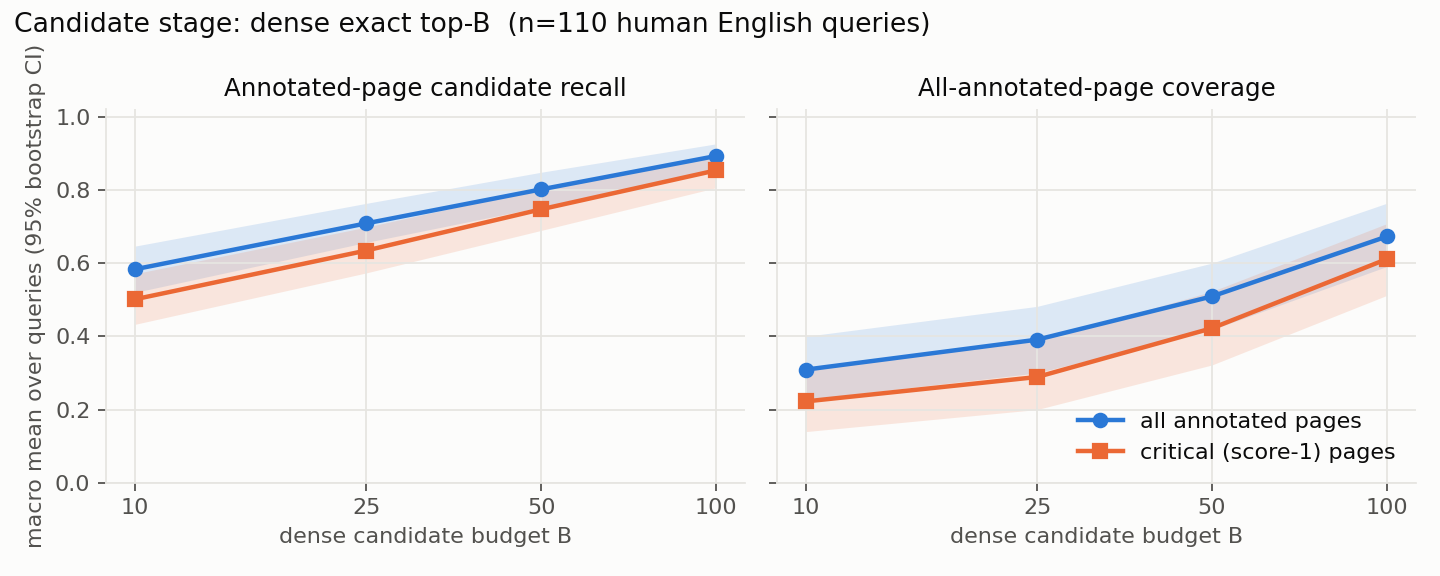

final_topk_before_after_rerank.png


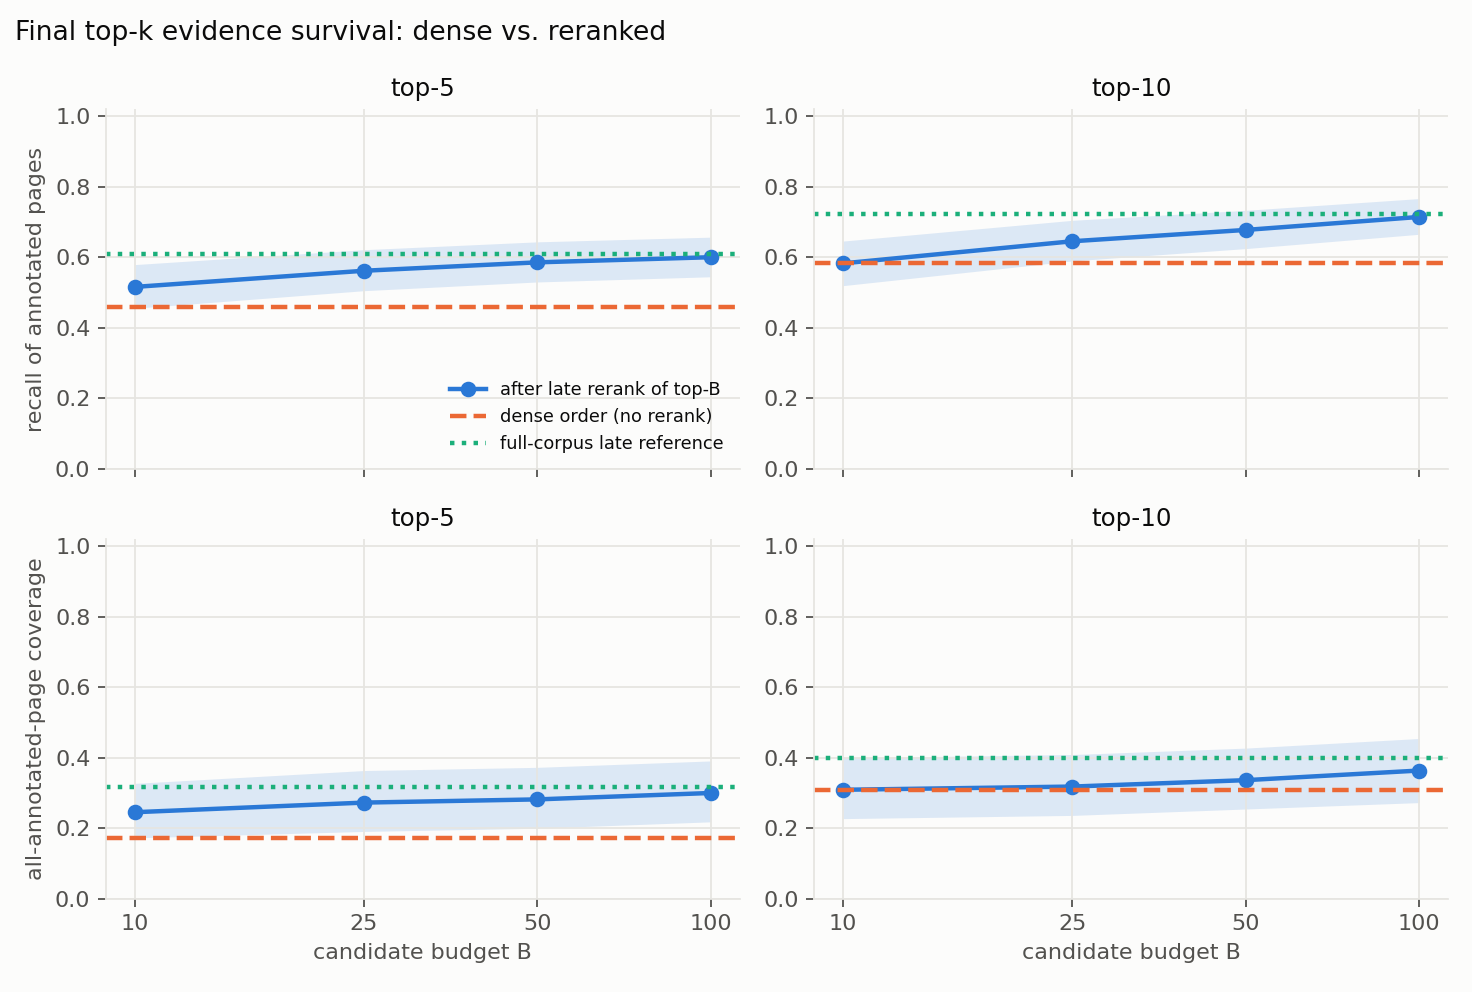

loss_distribution.png


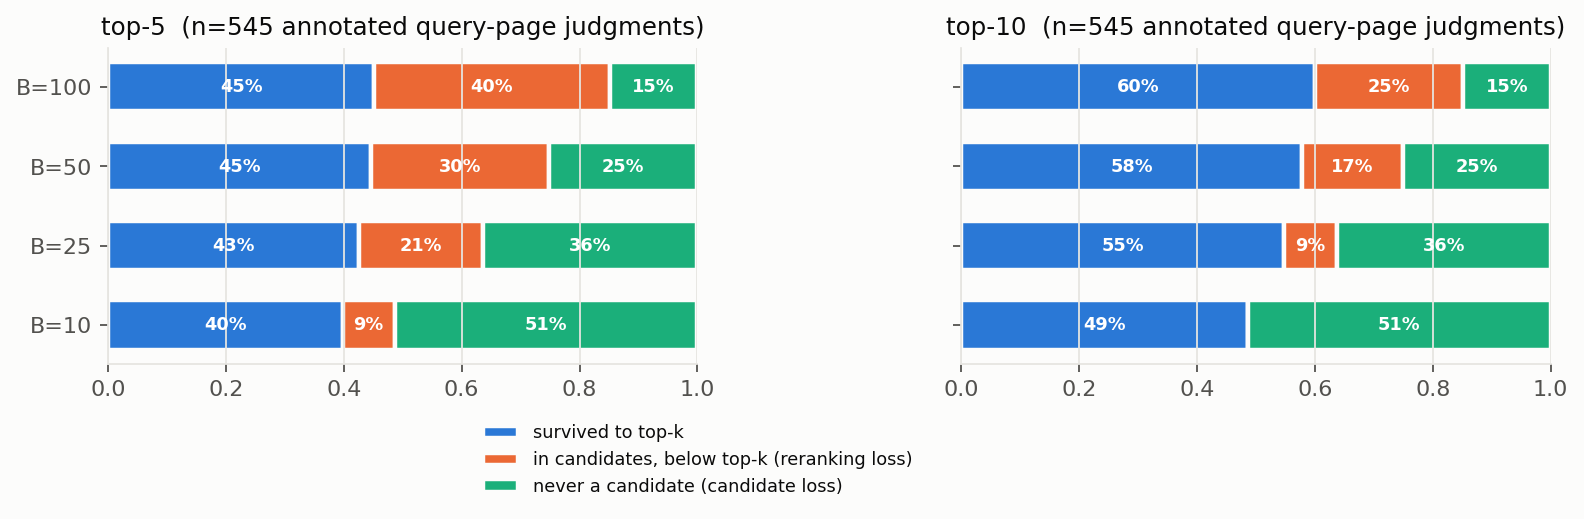

query_type_breakdown.png


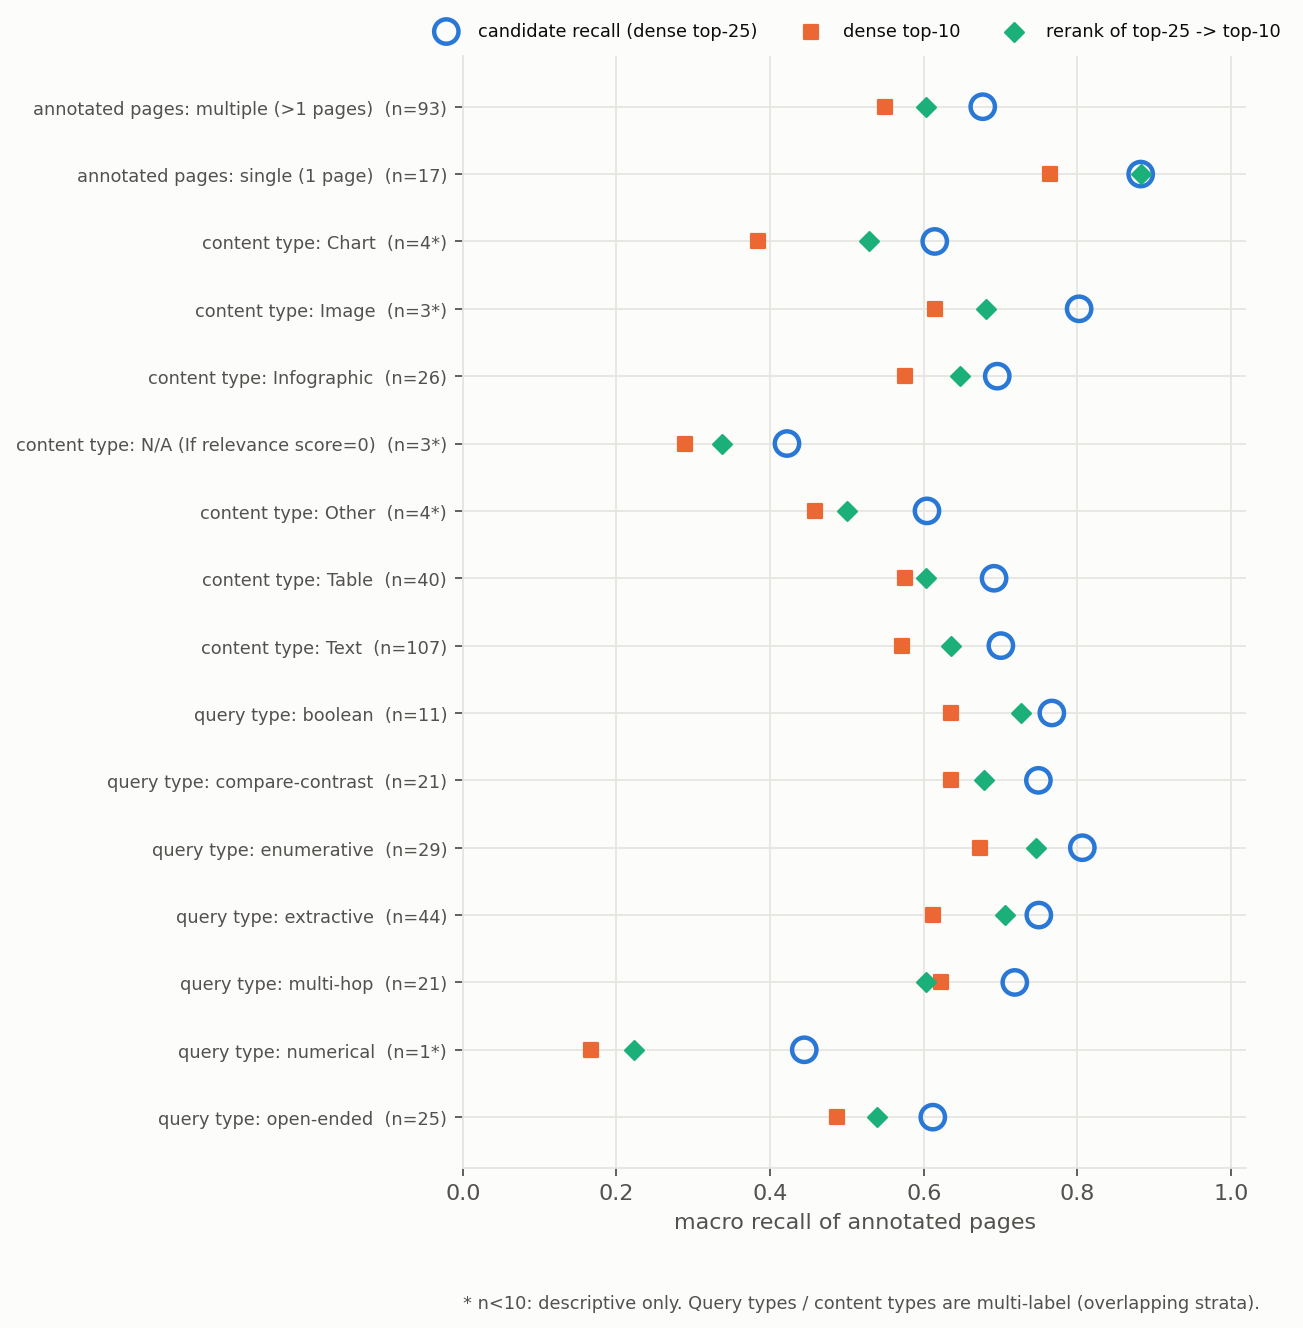

storage_and_timing.png


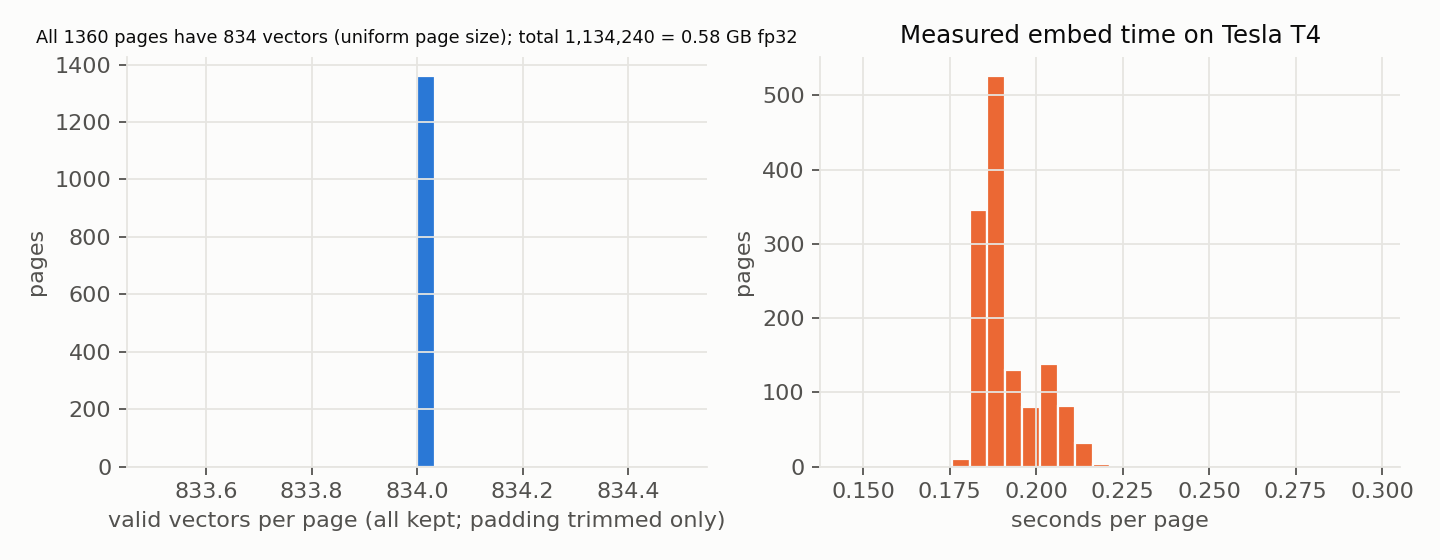

In [16]:
from IPython.display import Image
for p in sorted((run.dir / "plots").glob("*.png")):
    print(p.name); display(Image(str(p)))

In [17]:
# Trace viewer (real page thumbnails + human boxes for deterministically selected queries)
from IPython.display import IFrame, HTML
print("selection rules are printed inside the viewer; file:", run.dir / "trace_viewer.html")
display(HTML("<p>Open <code>trace_viewer.html</code> from the exported zip's run/ folder (thumbs are not exported; the viewer fetches page images on demand by row offset and verifies corpus_id).</p>"))

selection rules are printed inside the viewer; file: /content/vesk_work/runs/full-primary_1024-a5fda5219b/trace_viewer.html


## 13. Export (code, manifest, tables, plots, trace metadata, attribution; **no** images, embeddings or weights)

In [18]:
zip_path = run.export()
print(zip_path, round(zip_path.stat().st_size / 1e6, 2), "MB")
if IN_COLAB:
    from google.colab import files
    files.download(str(zip_path))

/content/vesk_work/export_full-primary_1024-a5fda5219b.zip 0.88 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Cleanup (stops the Qdrant subprocess; checkpoints are kept)

In [19]:
run.stop_qdrant(); run.save_manifest(); run.sync()
import gc, torch; run.enc = None; gc.collect(); torch.cuda.empty_cache() if torch.cuda.is_available() else None
print("qdrant stopped; manifest saved:", run.dir / "run_manifest.json")

qdrant stopped; manifest saved: /content/vesk_work/runs/full-primary_1024-a5fda5219b/run_manifest.json


## Handoff: what is and isn't established
- **Validated:** pinned API inspection; dataset invariants (110 queries / 545 judgments / 451+94); a complete smoke run on a Colab Tesla T4 (user-run) and on CPU with identical metrics; Qdrant-vs-torch parity ~1e-7; the optional full-corpus late reference verified against `mean_maxsim` (6e-8) on cached real vectors.
- **Not yet verified:** the full 1,360-page run itself, the 2048 px preset, `USE_DRIVE=True` resume, and the trace viewer in a browser. Timing/VRAM for the full run are whatever your run measures; projections are extrapolations.
- **Estimates only (before you run):** ~0.52 MB/page of float32 patch vectors at 1024 px square (planning envelope); actual sizes come from `storage_and_runtime.csv`.
- Expect an install-time **restart prompt** if Colab's preinstalled `transformers`/`datasets` differ from the pins.
- Licenses: annotations CC BY 4.0; page images inherit the OpenStax licenses (see `ATTRIBUTION.md` in the export); model Apache 2.0; code MIT.